# Bitcoin seven-day price forecast with ARIMA
Data: Blockchain.com *Market Price (USD)*, official chart API. This notebook runs the project modules in `src/`.

The commentary describes the saved snapshot (2025-11-25 to 2026-11-25). If you download new data, re-read the
outputs before relying on the text. **Statistical forecasts here are not investment advice.**

In [1]:
import sys, json, inspect
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
from IPython.display import Image, display, Code
from src import config, data_collection, preprocessing, stationarity, arima_model as am
import run_pipeline
pd.set_option("display.max_rows", 200); pd.set_option("display.width", 200)
show = lambda name: display(Image(filename=str(config.OUTPUT_DIR / name), width=950))
table = lambda name: pd.read_csv(config.RESULTS_DIR / name)
src = lambda obj: display(Code(inspect.getsource(obj), language="python"))

## 1. Data collection
The saved snapshot is loaded and its SHA-256 checksum verified. The metric is the average USD market price across major exchanges, as defined by the API.

In [2]:
raw, metadata = data_collection.load_data()
print(json.dumps(metadata, indent=2))
display(raw.head(), raw.tail()); print(raw.dtypes); print("Missing values:\n", raw.isna().sum())

{
  "source": "Blockchain.com Charts API",
  "chart_page": "https://www.blockchain.com/ko/charts/market-price",
  "request_url": "https://api.blockchain.info/charts/market-price?timespan=1year&format=json&sampled=false",
  "retrieved_utc": "2026-11-25 05:11:32 UTC",
  "metric_name": "Market Price (USD)",
  "metric_description": "Average USD market price across major bitcoin exchanges.",
  "unit": "USD",
  "period": "day",
  "observations": 366,
  "csv_sha256": "247e3fa4cf7763584543337cc004507351c8f6bbb1a6201fe023f785d99829d4"
}


,date,timestamp,market_price_usd
0,2025-11-25 00:00:00,1764028800,88276.26
1,2025-11-26 00:00:00,1764115200,87330.85
2,2025-11-27 00:00:00,1764201600,90517.55
3,2025-11-28 00:00:00,1764288000,91305.47
4,2025-11-29 00:00:00,1764374400,90915.26


,date,timestamp,market_price_usd
361,2026-11-21 00:00:00,1795219200,58786.67
362,2026-11-22 00:00:00,1795305600,60088.31
363,2026-11-23 00:00:00,1795392000,61081.74
364,2026-11-24 00:00:00,1795478400,61214.41
365,2026-11-25 00:00:00,1795564800,59742.21


date                    str
timestamp             int64
market_price_usd    float64
dtype: object
Missing values:
 date                0
timestamp           0
market_price_usd    0
dtype: int64


## 2. Preprocessing
Dates are parsed and sorted, duplicates and gaps checked, and positivity verified. Forward filling (past information only) is the declared gap rule; this snapshot needed none.

In [3]:
src(preprocessing.clean_data)
price, quality = preprocessing.clean_data(raw); quality

def clean_data(raw: pd.DataFrame):
    """Return (daily price Series, quality report).

    Gaps, if any, are forward-filled: this uses only past information, so it
    cannot leak future prices into the model.
    """
    frame = raw.copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="raise").dt.normalize()
    frame["market_price_usd"] = pd.to_numeric(frame["market_price_usd"], errors="coerce")
    non_numeric = int(frame["market_price_usd"].isna().sum())
    non_positive = int((frame["market_price_usd"] <= 0).sum())
    frame.loc[frame["market_price_usd"] <= 0, "market_price_usd"] = np.nan
    was_sorted = bool(frame["date"].is_monotonic_increasing)
    frame = frame.sort_values("timestamp")
    duplicates = int(frame["date"].duplicated().sum())
    frame = frame.drop_duplicates("date", keep="last").set_index("date")

    calendar = pd.date_range(frame.index.min(), frame.index.max(), freq="D", name="date")
    missing_dates = len(calendar.difference(frame.index))
    series = frame["market_price_usd"].reindex(calendar)
    values_to_fill = int(series.isna().sum())
    series = series.ffill().dropna().astype(float).asfreq("D")
    if series.empty or not (series > 0).all():
        raise ValueError("Cleaned series is empty or contains non-positive prices.")

    report = {
        "raw_rows": int(len(raw)), "clean_rows": int(len(series)),
        "start_date": str(series.index[0].date()), "end_date": str(series.index[-1].date()),
        "originally_sorted": was_sorted, "duplicate_dates": duplicates,
        "missing_calendar_dates": missing_dates, "non_numeric_values": non_numeric,
        "non_positive_values": non_positive, "values_forward_filled": values_to_fill,
        "frequency": series.index.freqstr,
    }
    return series.rename("price"), report

{'raw_rows': 366,
 'clean_rows': 366,
 'start_date': '2025-11-25',
 'end_date': '2026-11-25',
 'originally_sorted': True,
 'duplicate_dates': 0,
 'missing_calendar_dates': 0,
 'non_numeric_values': 0,
 'non_positive_values': 0,
 'values_forward_filled': 0,
 'frequency': 'D'}

## 3. Run the full analysis
This fits the 128-model grid and all walk-forward evaluations (several minutes). The following sections inspect its outputs.

In [4]:
summary = run_pipeline.main()

1/6 Data collection and cleaning
2/6 Exploratory analysis


3/6 Stationarity, ACF and PACF (d chosen from training data)


4/6 Model search and selection (training data only)


    selected: ARIMA(0, 1, 0)
5/6 Hold-out evaluation and diagnostics


6/6 Final refit and seven-day forecast


forecast_date  horizon_days  predicted_price_usd  lower_95_usd  upper_95_usd  expected_daily_change_pct  cumulative_change_pct direction
   2026-11-26             1             59742.21  57075.638356  62533.363769                        0.0                    0.0   Neutral
   2026-11-27             2             59742.21  56006.278021  63727.349537                        0.0                    0.0   Neutral
   2026-11-28             3             59742.21  55199.334004  64658.962288                        0.0                    0.0   Neutral
   2026-11-29             4             59742.21  54528.087954  65454.920384                        0.0                    0.0   Neutral
   2026-11-30             5             59742.21  53943.475175  66164.288528                        0.0                    0.0   Neutral
   2026-12-01             6             59742.21  53420.341421  66812.220977                        0.0                    0.0   Neutral
   2026-12-02             7             5

## 4. Exploratory data analysis

In [5]:
display(table('descriptive_statistics.csv'), table('monthly_average_price.csv'))

,Unnamed: 0,Price (USD),Daily change (USD),Daily return (%)
0,count,366.000000,365.000000,365.000000
1,mean,75265.677158,-78.175479,-0.079886
2,std,9752.099227,1713.457761,2.325658
3,min,58534.280000,-10192.120000,-13.961009
4,25%,65986.237500,-1015.730000,-1.390530
5,50%,75802.575000,-32.030000,-0.041841
6,75%,82145.985000,710.570000,0.934776
7,max,96931.940000,7708.260000,12.271943
8,skewness,0.211527,-0.135339,0.068322
9,excess kurtosis,-1.086916,4.974774,5.896618


,date,mean,count
0,2025-11-01,89862.701667,6
1,2025-12-01,89010.155161,31
2,2026-01-01,90749.641613,31
3,2026-02-01,69229.641429,28
4,2026-03-01,69447.343548,31
5,2026-04-01,73476.721333,30
6,2026-05-01,78066.470000,31
7,2026-06-01,63502.693333,30
8,2026-07-01,63723.942903,31
9,2026-08-01,68978.168387,31


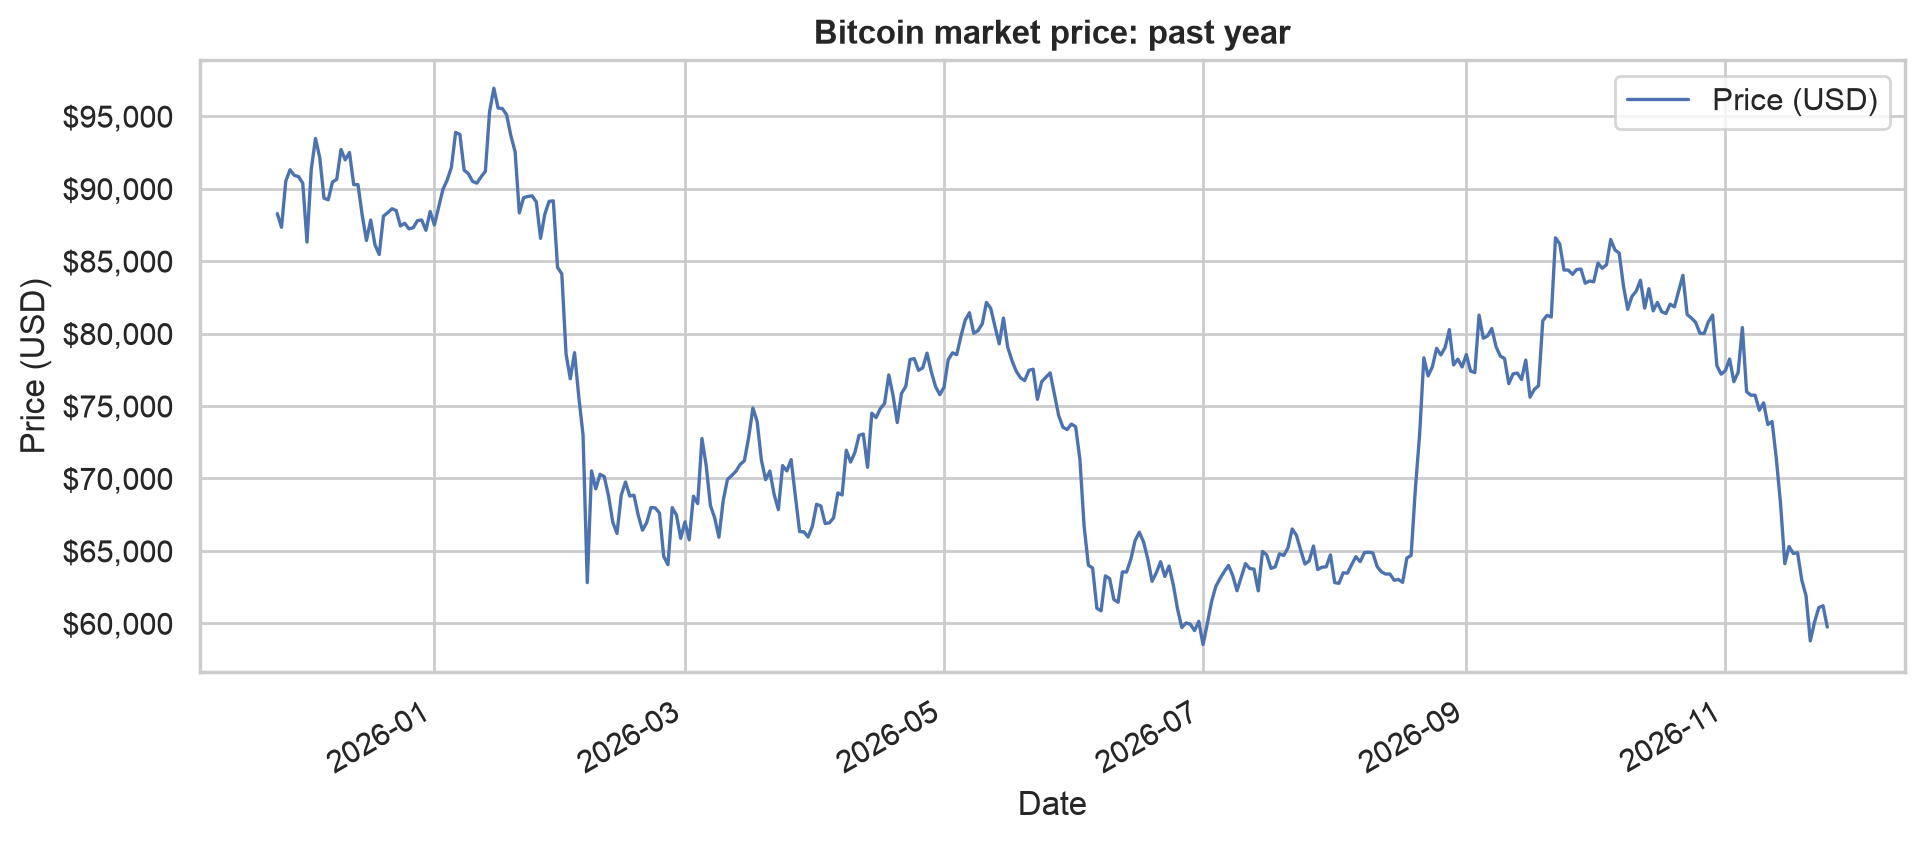

In [6]:
show('historical_price.png')

Large swings with no stable level: peak in January 2026, low on 1 July 2026, and a sharp fall in November.

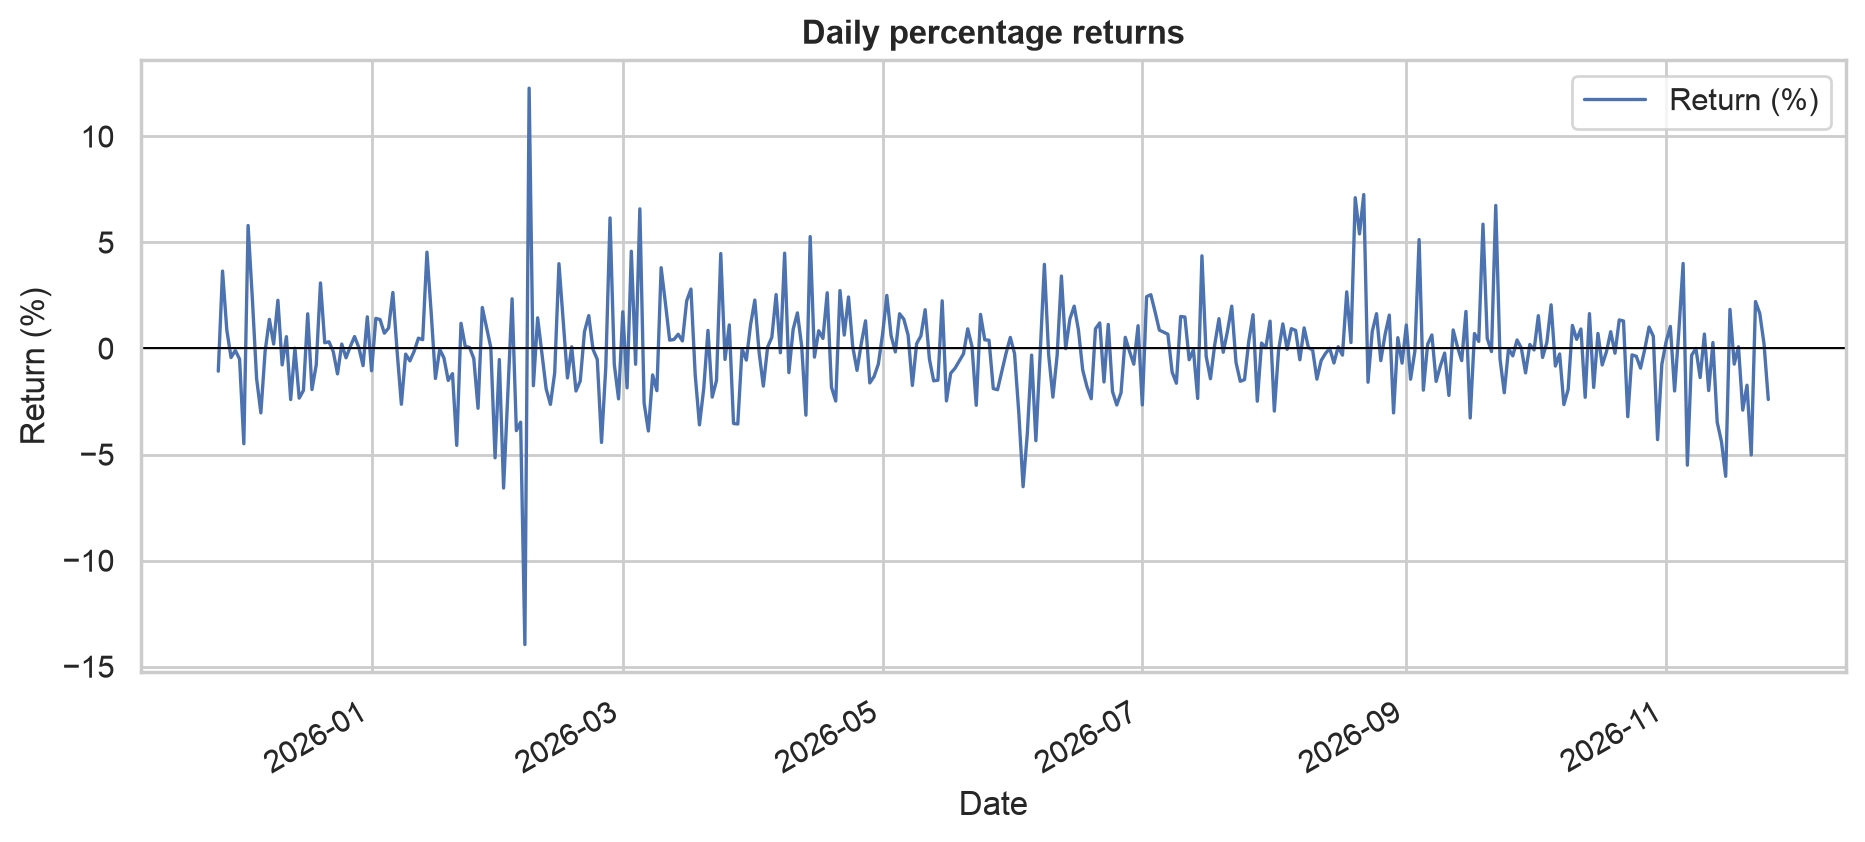

In [7]:
show('daily_returns.png')

Returns centre near zero with clustered, heavy-tailed shocks; the largest fall and gain occur on 6 and 7 February 2026.

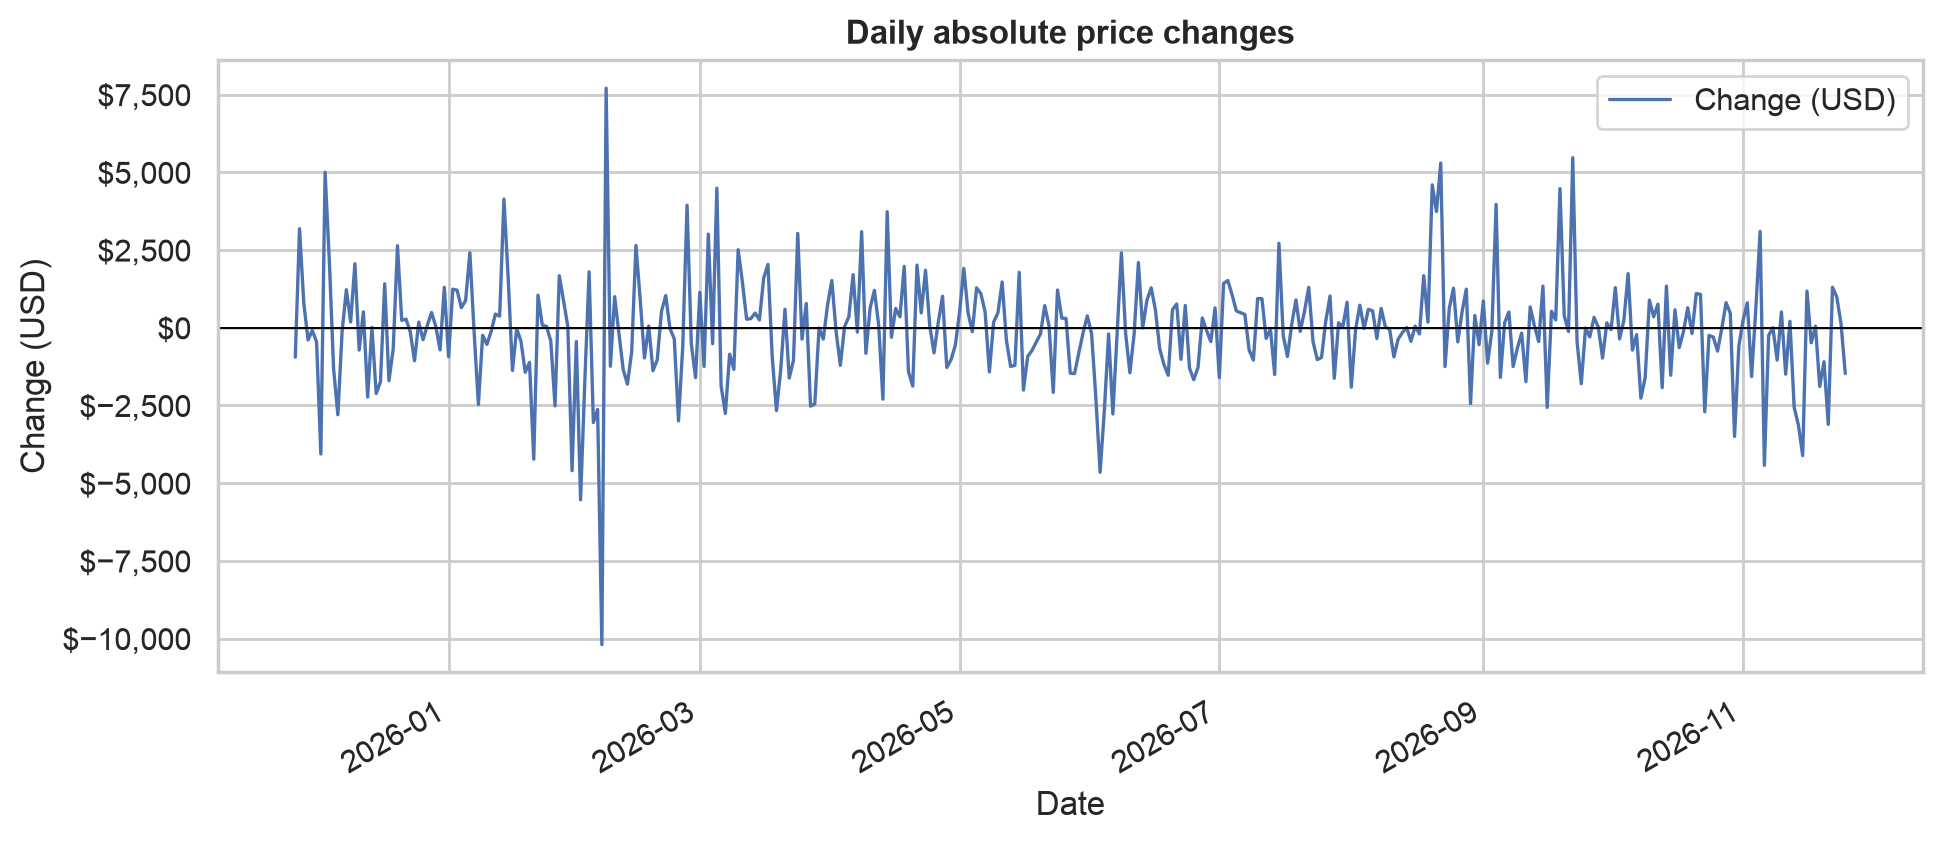

In [8]:
show('daily_changes.png')

Dollar changes show the same bursts of volatility.

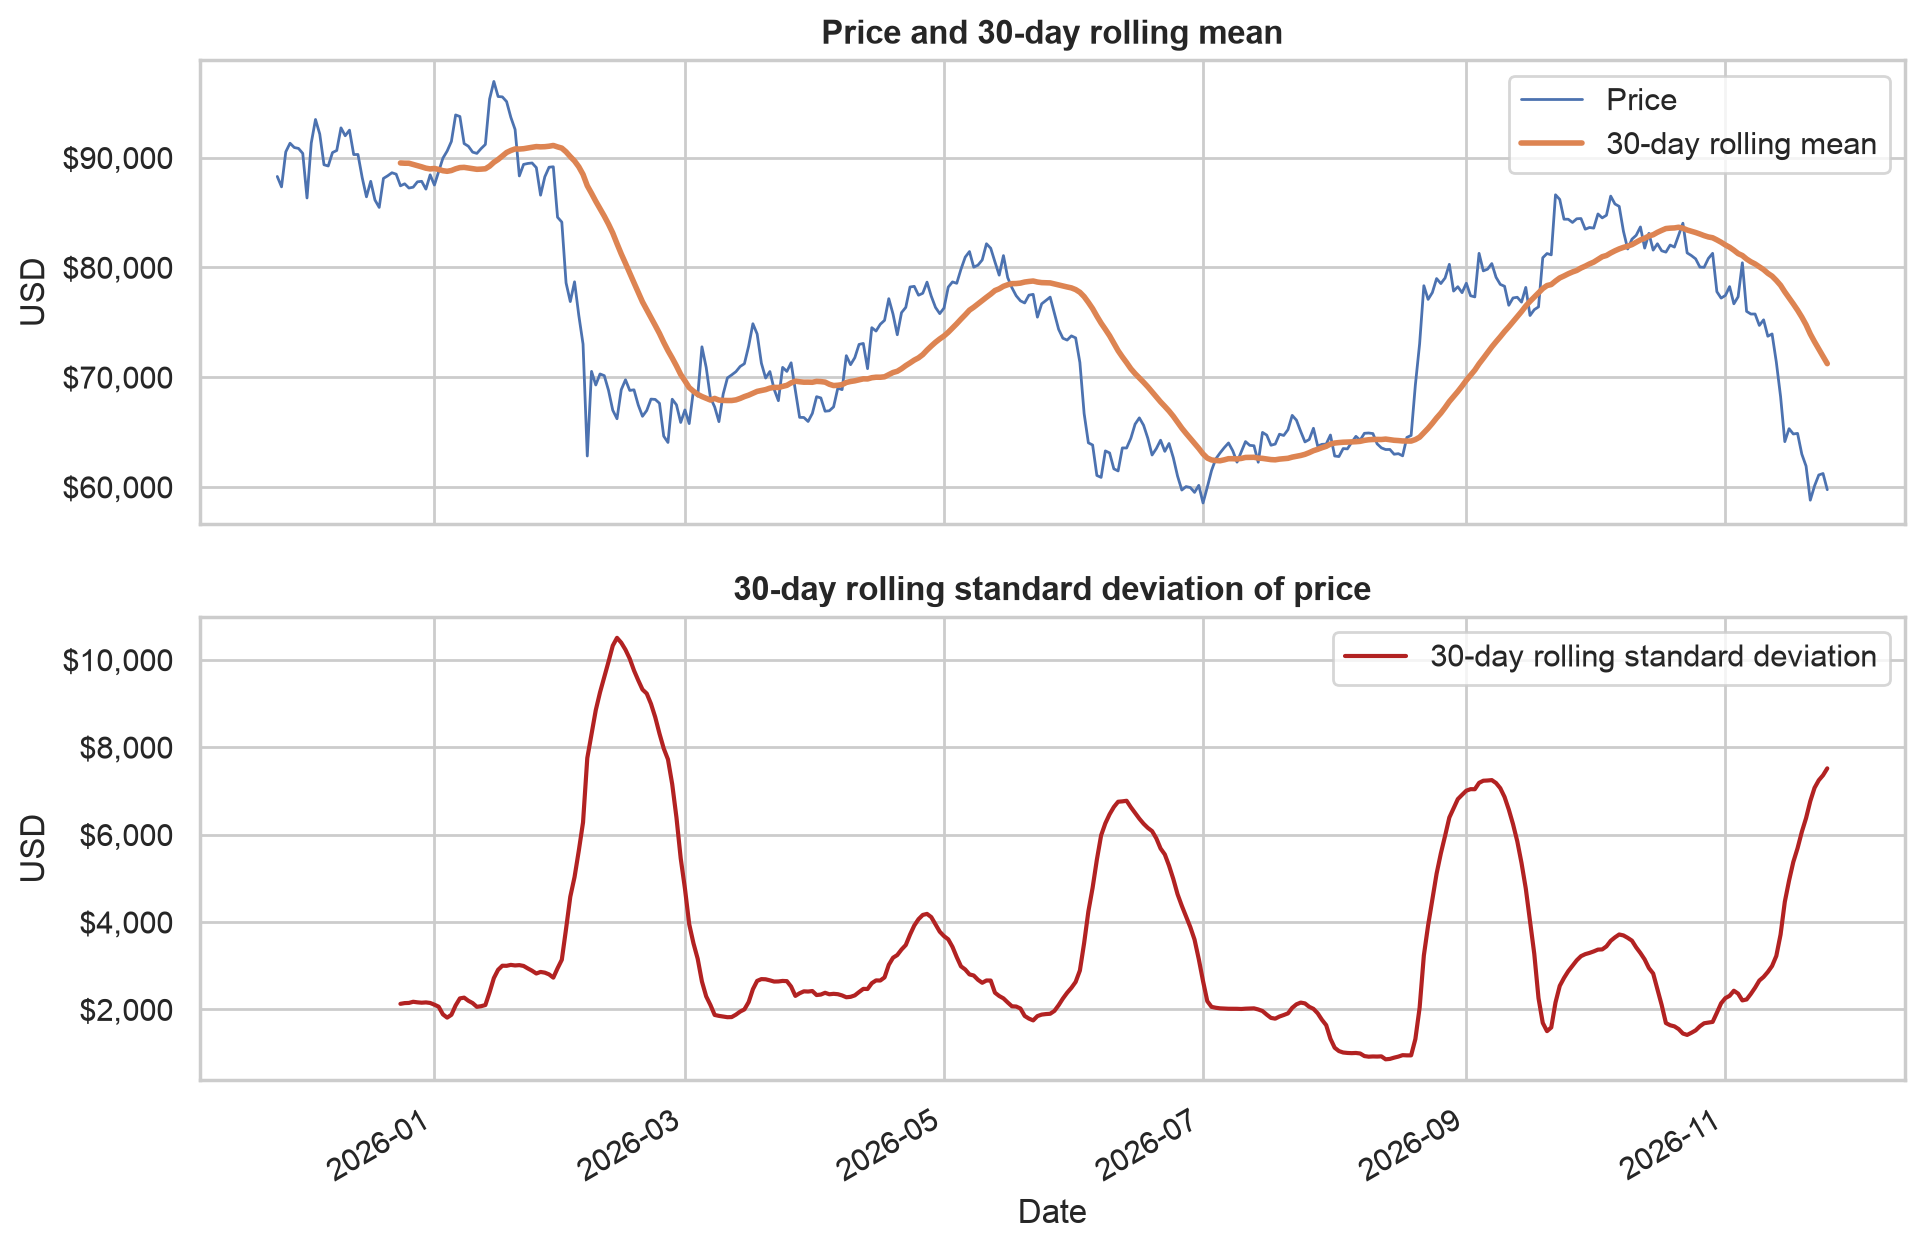

In [9]:
show('rolling_statistics.png')

Both the 30-day mean and standard deviation change over time, suggesting non-stationarity.

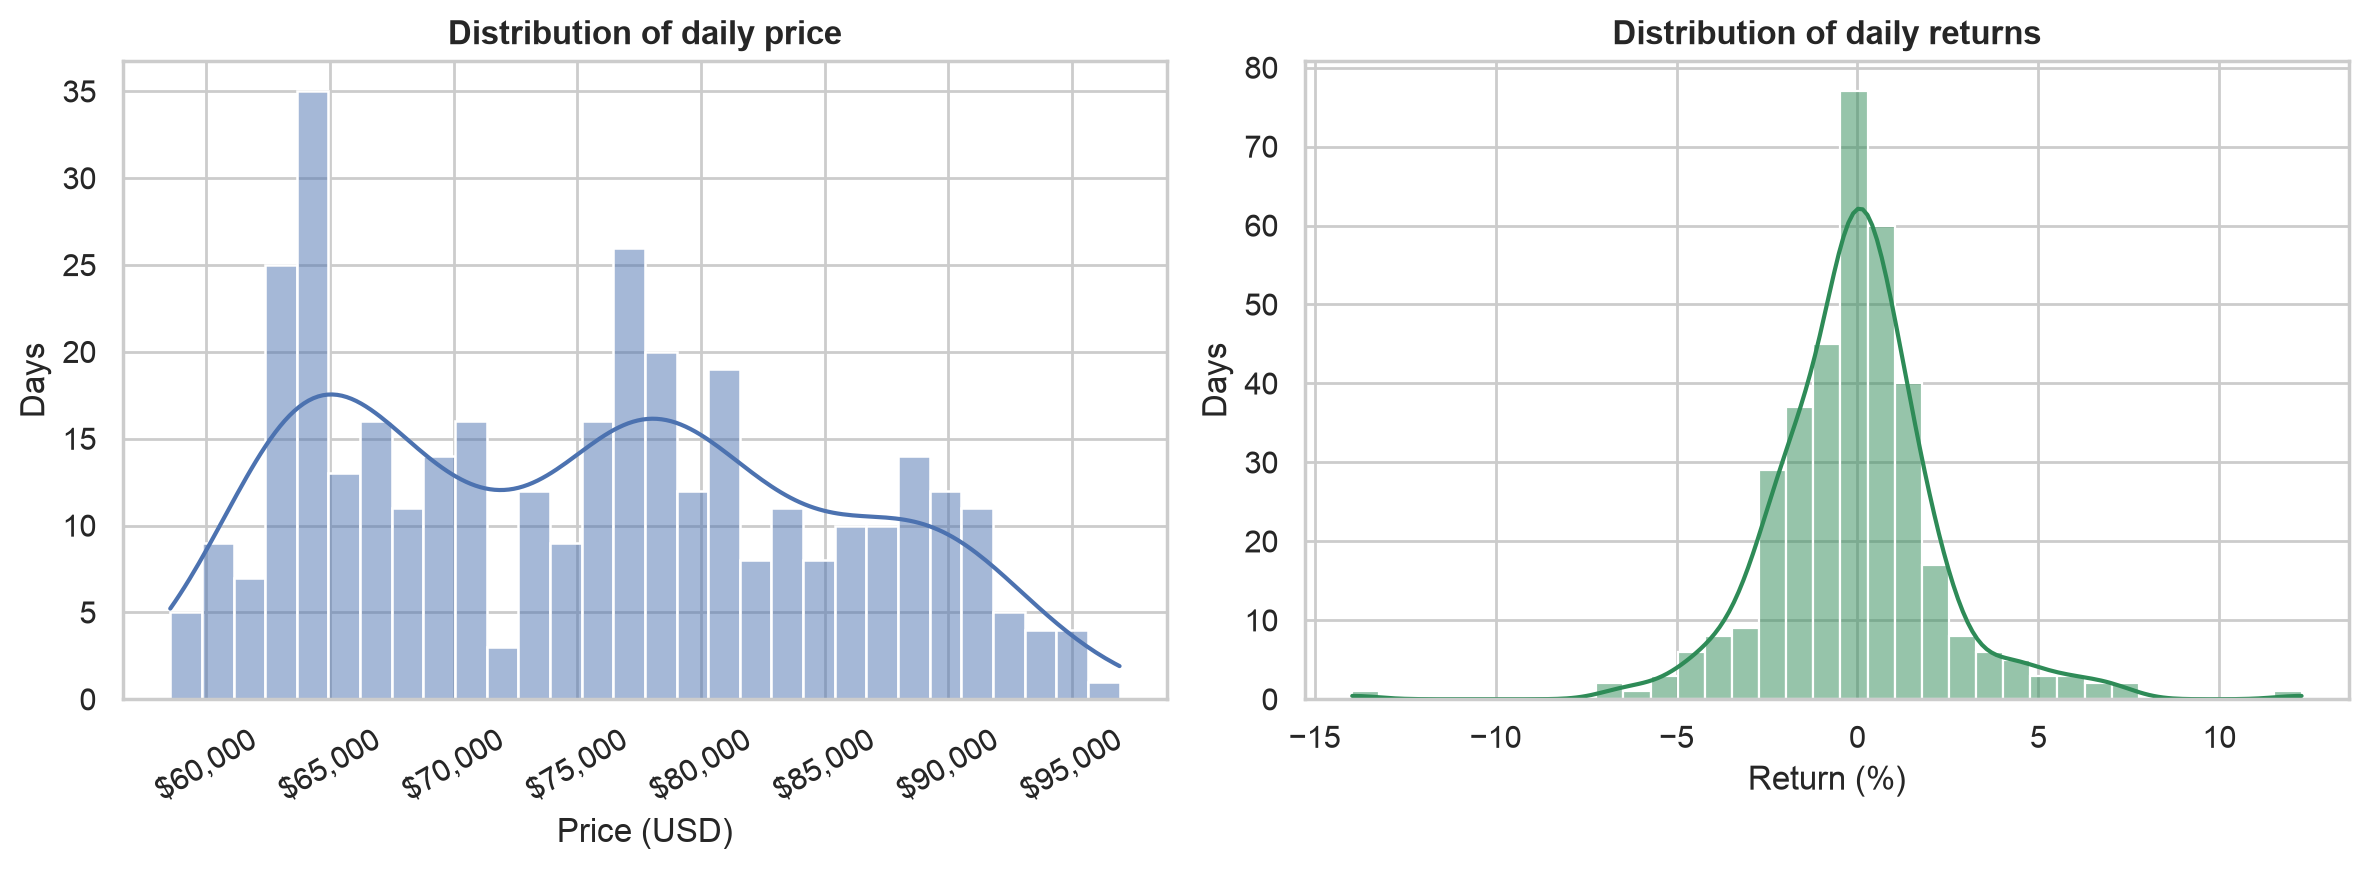

In [10]:
show('price_distribution.png')

Price levels are multi-modal (market phases); returns are peaked with heavy tails.

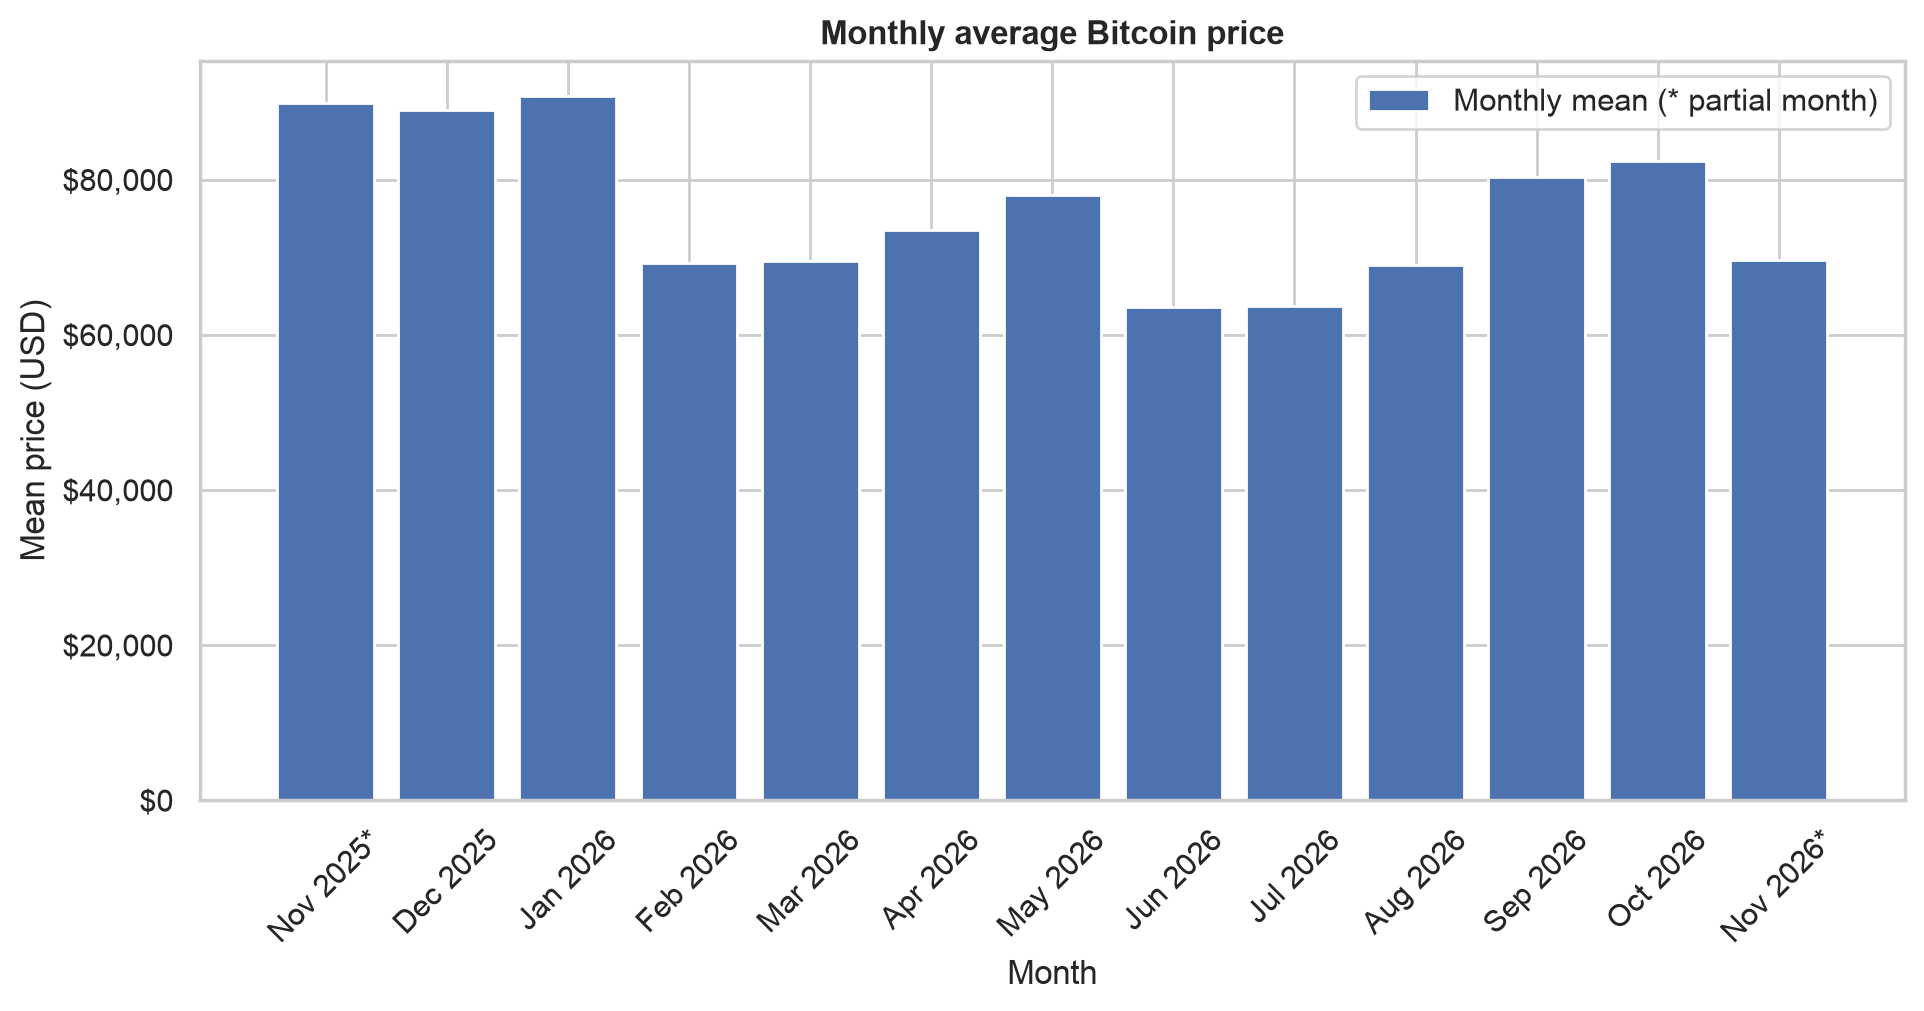

In [11]:
show('monthly_average_price.png')

Highest monthly mean: January 2026; lowest: June 2026. Starred months are partial.

## 5. Stationarity
ARIMA needs a stationary differenced series. **ADF:** H0 unit root, H1 stationary. **KPSS:** H0 stationary, H1 unit root.

,sample,series,test,deterministic,statistic,p_value,lags,crit_1pct,crit_5pct,crit_10pct,conclusion_5pct
0,Training,Price,ADF,constant,-1.7571,0.4020,0,-3.4530,-2.8715,-2.5721,Non-stationary
1,Training,Price,KPSS,constant,1.3273,0.0100,10,0.7390,0.4630,0.3470,Non-stationary
2,Training,Price,ADF,constant + trend,-1.4864,0.8337,0,-3.9902,-3.4257,-3.1360,Non-stationary
3,Training,Price,KPSS,constant + trend,0.2469,0.0100,10,0.2160,0.1460,0.1190,Non-stationary
4,Training,Log price,ADF,constant,-1.7871,0.3869,0,-3.4530,-2.8715,-2.5721,Non-stationary
5,Training,Log price,KPSS,constant,1.2973,0.0100,10,0.7390,0.4630,0.3470,Non-stationary
6,Training,Log price,ADF,constant + trend,-1.5294,0.8189,0,-3.9902,-3.4257,-3.1360,Non-stationary
7,Training,Log price,KPSS,constant + trend,0.2284,0.0100,10,0.2160,0.1460,0.1190,Non-stationary
8,Training,Differenced price,ADF,constant,-17.3071,0.0000,0,-3.4531,-2.8716,-2.5721,Stationary
9,Training,Differenced price,KPSS,constant,0.1651,0.1000,3,0.7390,0.4630,0.3470,Stationary


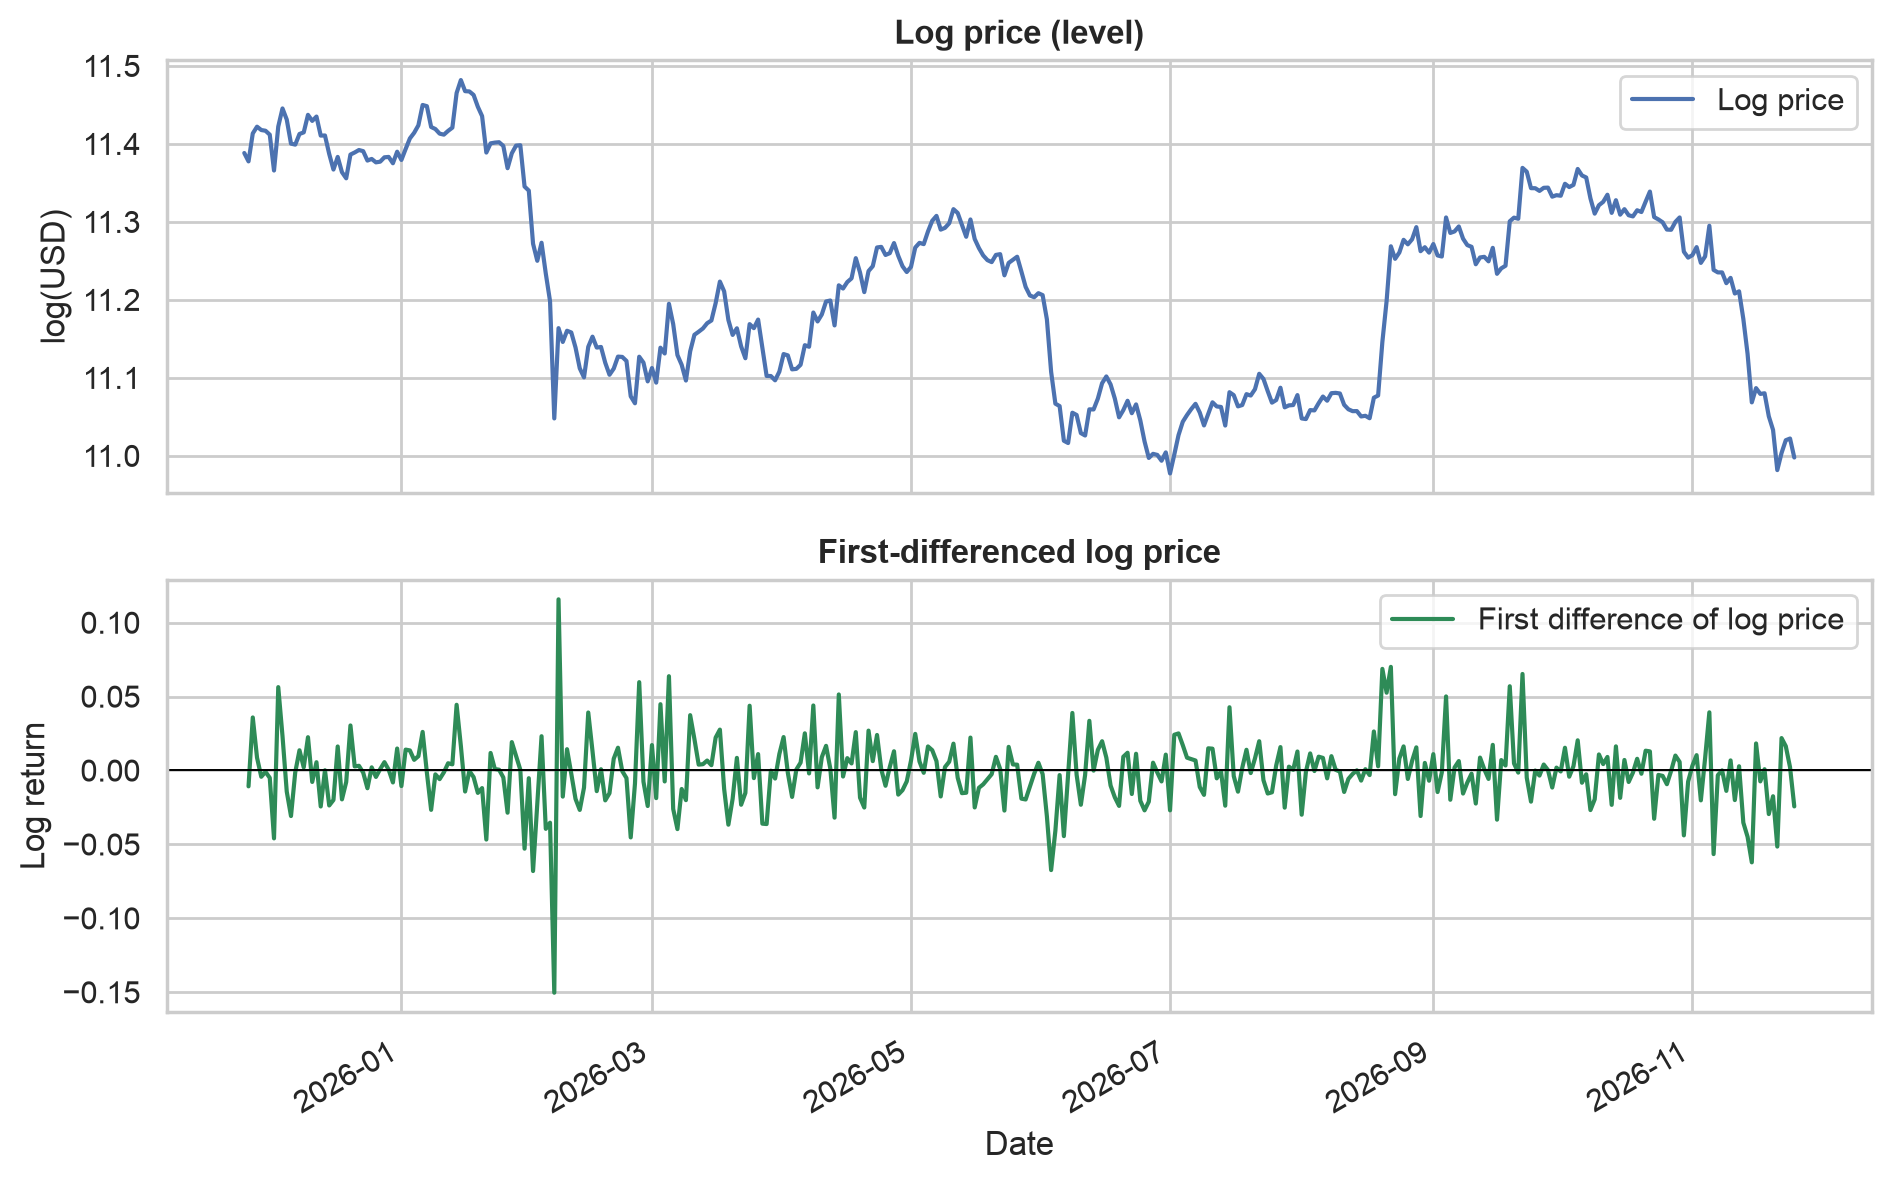

d = 1


In [12]:
display(table('stationarity_tests.csv').round(4)); show('differencing.png'); print('d =', summary['d'])

Levels fail to reject the ADF unit root and are rejected by KPSS; first differences reverse both results. Therefore d = 1, determined on training data.

## 6. ACF and PACF

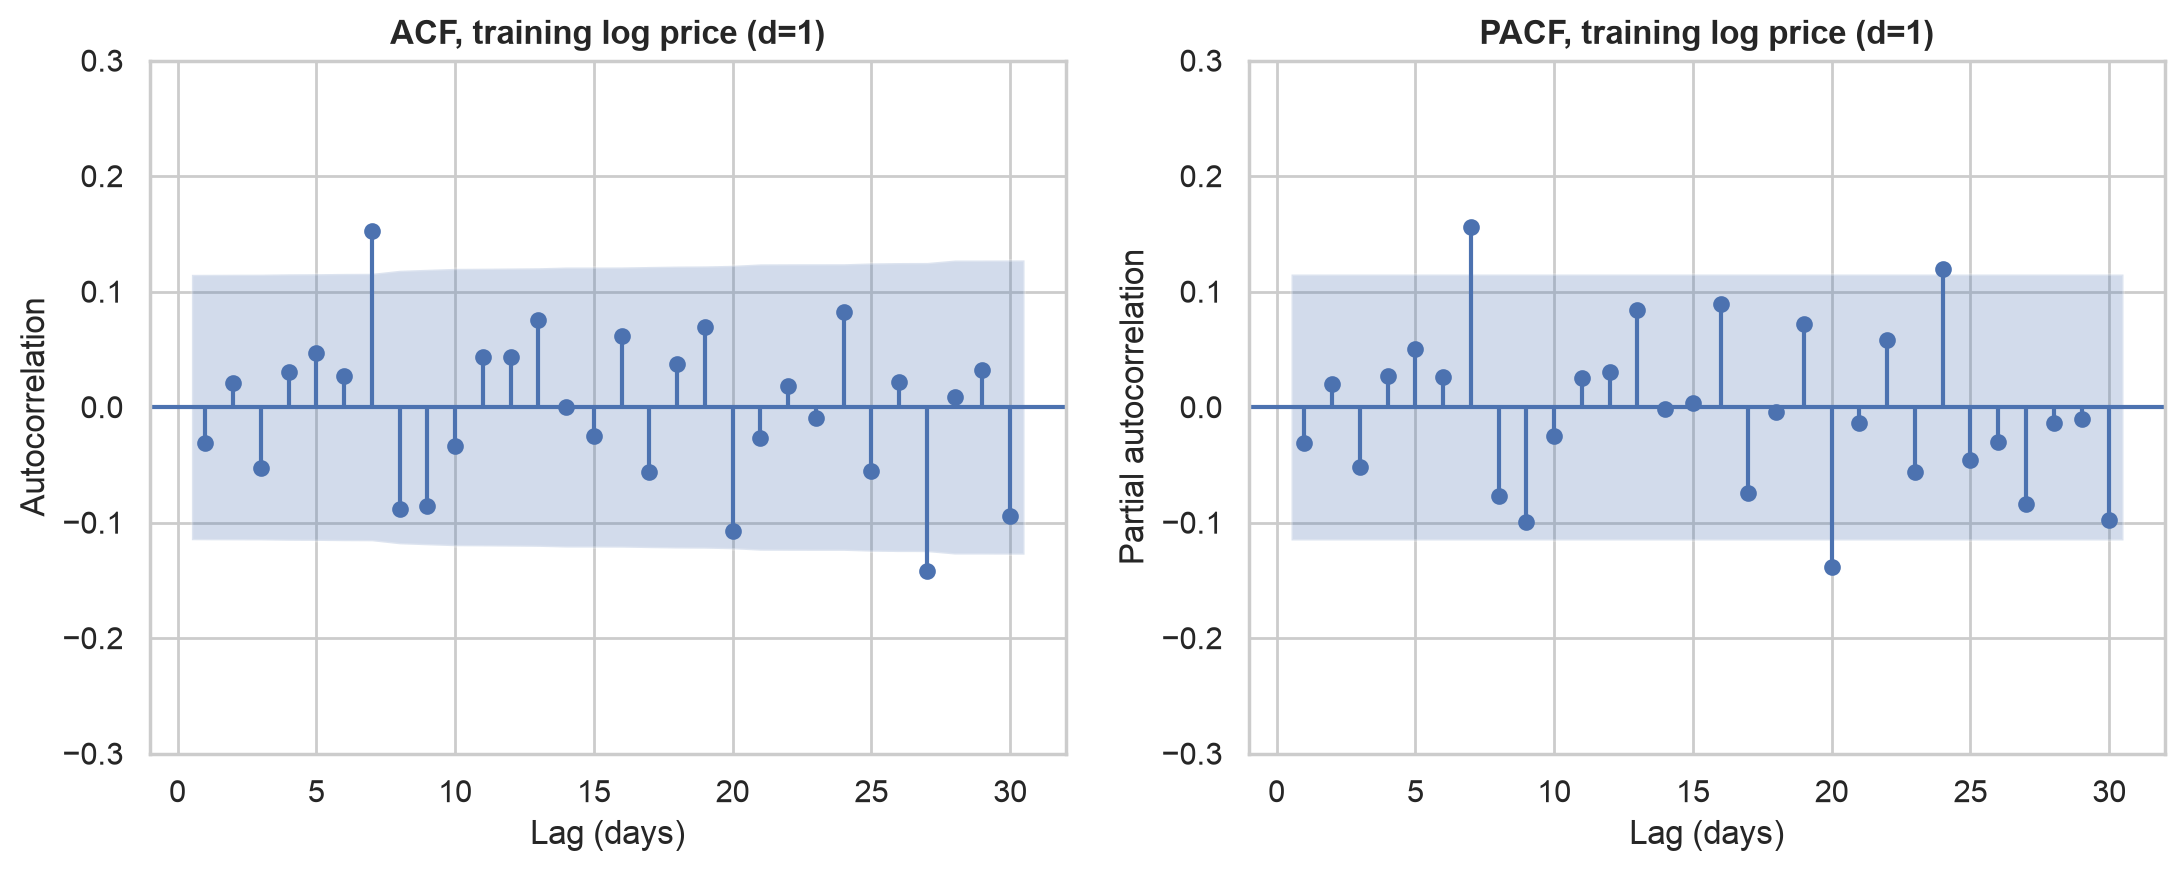

{'n': 291,
 'bound': 0.11489723482506764,
 'significant_acf': [[7, 0.15228317902687014], [27, -0.14199740434608524]],
 'significant_pacf': [[7, 0.1561776939364164],
  [20, -0.1380932628897749],
  [24, 0.11909877281457838]]}

In [13]:
show('acf_pacf.png'); summary['correlation']

Lags 1–6 are insignificant. Isolated spikes (notably lag 7) guided a search to p, q ≤ 7. With 30 lags some spikes arise by chance, bounds assume homoskedastic noise, and mixed models have no clean cut-off, so the plots do not choose the model.

## 7. Model development and selection (training data only)
Shortlist by AIC, BIC, auto_arima and the random walk; screen convergence, Ljung–Box and AR/MA roots (≥ 1.001); then compare seven-day rolling-origin validation RMSE.

**Disclosure:** the first run had no root screen and chose ARIMA(6,1,4), whose MA roots lie on the unit circle. The screen was added after results had been seen; ARIMA(6,1,4) is kept as a sensitivity analysis.

In [14]:
src(am.select_model)
grid = table('arima_grid_search.csv'); display(grid.nsmallest(8, 'aic'), grid.nsmallest(8, 'bic'))
display(table('candidate_comparison.csv').round(4)); print(summary['selected'], 'auto_arima:', summary['auto_arima'])

def select_model(price, grid, train_size, auto_choice):
    """Pre-declared rule, using training data only.

    1. Shortlist: top 5 by AIC, top 5 by BIC, auto_arima choice, random walk.
    2. Reject non-converged models, Ljung-Box p < 0.05, or any AR/MA root with
       modulus below 1.001 (Hyndman & Khandakar, 2008).  The root screen was added
       after a first run selected a model with MA roots on the unit circle; the
       result without it is retained as a sensitivity analysis.
    3. Compare 7-day rolling-origin RMSE on the last 20% of the training set.
    4. Among models within 1% of the best RMSE choose the fewest parameters, then lowest BIC.
    """
    d = int(grid["d"].iloc[0])
    wanted = {}
    for source, subset in (("AIC top 5", grid.nsmallest(5, "aic")),
                           ("BIC top 5", grid.nsmallest(5, "bic"))):
        for r in subset.itertuples():
            wanted.setdefault(((r.p, r.d, r.q), r.trend), []).append(source)
    wanted.setdefault(auto_choice, []).append("auto_arima")
    wanted.setdefault(((0, d, 0), "n"), []).append("random walk")

    validation_start = train_size - int(round(train_size * config.VALIDATION_FRACTION))
    rows = []
    for (order, trend), sources in wanted.items():
        info = grid[(grid.p == order[0]) & (grid.q == order[2]) & (grid.trend == trend)].iloc[0]
        one = metrics(walk_forward(price, order, trend, validation_start, train_size, 1))
        week = metrics(walk_forward(price, order, trend, validation_start, train_size, config.HORIZON))
        rows.append({"model": label(order, trend), "p": order[0], "d": order[1], "q": order[2],
                     "trend": trend, "shortlisted_by": "; ".join(sources),
                     "n_parameters": order[0] + order[2] + (trend == "t") + 1,
                     "aic": info.aic, "bic": info.bic, "min_ljung_box_p": info.min_ljung_box_p,
                     "converged": info.converged, "min_root_modulus": info.min_root_modulus,
                     "val_RMSE_1step": one["RMSE"],
                     "val_RMSE_7day": week["RMSE"], "val_MAPE_7day": week["MAPE_%"]})
    table = pd.DataFrame(rows)
    table["passes_diagnostics"] = table.converged & (table.min_ljung_box_p >= config.ALPHA)
    table["admissible_roots"] = table.min_root_modulus >= config.MIN_ROOT_MODULUS

    def choose(mask):
        eligible = table[mask]
        if eligible.empty:
            raise RuntimeError("No shortlisted model passes the screen; revise the search space.")
        tied = eligible[eligible.val_RMSE_7day <= eligible.val_RMSE_7day.min()
                        * (1 + config.PARSIMONY_TOLERANCE)]
        return tied.sort_values(["n_parameters", "bic"]).iloc[0]

    winner = choose(table.passes_diagnostics & table.admissible_roots)
    unscreened = choose(table.passes_diagnostics)
    table["selected"] = table.model == winner.model
    table["selected_without_root_screen"] = table.model == unscreened.model
    table = table.sort_values("val_RMSE_7day").reset_index(drop=True)
    table.to_csv(config.RESULTS_DIR / "candidate_comparison.csv", index=False)
    order = (int(winner.p), int(winner.d), int(winner.q))
    return order, winner.trend, table, validation_start

,p,d,q,trend,model,aic,bic,converged,min_root_modulus,min_ljung_box_p
0,6,1,5,n,"ARIMA(6, 1, 5)",-1361.303779,-1317.223900,True,1.000036,0.359711
1,4,1,4,n,"ARIMA(4, 1, 4)",-1360.819164,-1327.759254,True,1.000012,0.009843
2,4,1,5,n,"ARIMA(4, 1, 5)",-1359.935277,-1323.202044,True,1.000000,0.023019
3,6,1,4,n,"ARIMA(6, 1, 4)",-1359.237209,-1318.830653,True,1.000004,0.173015
4,3,1,2,n,"ARIMA(3, 1, 2)",-1358.885947,-1336.846007,True,1.001182,0.065836
5,4,1,6,n,"ARIMA(4, 1, 6)",-1358.505235,-1318.098679,True,1.001453,0.199845
6,7,1,6,n,"ARIMA(7, 1, 6)",-1358.064757,-1306.638232,True,1.000880,0.241694
7,4,1,5,t,"ARIMA(4, 1, 5) + drift",-1358.042715,-1317.636159,True,1.000000,0.022993


,p,d,q,trend,model,aic,bic,converged,min_root_modulus,min_ljung_box_p
35,0,1,0,n,"ARIMA(0, 1, 0)",-1351.445840,-1347.772516,True,inf,0.162911
40,1,1,0,n,"ARIMA(1, 1, 0)",-1349.721147,-1342.374500,False,32.465910,0.121467
41,0,1,1,n,"ARIMA(0, 1, 1)",-1349.710783,-1342.364137,True,34.556560,0.121716
42,0,1,0,t,"ARIMA(0, 1, 0) + drift",-1349.556067,-1342.209420,True,inf,0.162911
45,1,1,1,n,"ARIMA(1, 1, 1)",-1348.040711,-1337.020741,True,1.795136,0.083285
4,3,1,2,n,"ARIMA(3, 1, 2)",-1358.885947,-1336.846007,True,1.001182,0.065836
46,2,1,0,n,"ARIMA(2, 1, 0)",-1347.841717,-1336.821747,True,6.338048,0.077445
47,1,1,0,t,"ARIMA(1, 1, 0) + drift",-1347.838350,-1336.818380,False,32.062152,0.121431


,model,p,d,q,trend,shortlisted_by,n_parameters,aic,bic,min_ljung_box_p,converged,min_root_modulus,val_RMSE_1step,val_RMSE_7day,val_MAPE_7day,passes_diagnostics,admissible_roots,selected,selected_without_root_screen
0,"ARIMA(6, 1, 4)",6,1,4,n,AIC top 5,11,-1359.2372,-1318.8307,0.1730,True,1.0000,1479.3476,3679.0522,2.7387,True,False,False,True
1,"ARIMA(6, 1, 5)",6,1,5,n,AIC top 5,12,-1361.3038,-1317.2239,0.3597,True,1.0000,1504.8562,3721.2965,2.8851,True,False,False,False
2,"ARIMA(0, 1, 0)",0,1,0,n,BIC top 5; auto_arima; random walk,1,-1351.4458,-1347.7725,0.1629,True,inf,1444.3415,3742.4762,2.8980,True,True,True,False
3,"ARIMA(4, 1, 4)",4,1,4,n,AIC top 5,9,-1360.8192,-1327.7593,0.0098,True,1.0000,1521.1851,3746.6584,2.9582,False,False,False,False
4,"ARIMA(4, 1, 5)",4,1,5,n,AIC top 5,10,-1359.9353,-1323.2020,0.0230,True,1.0000,1437.6985,3746.7725,2.8697,False,False,False,False
5,"ARIMA(3, 1, 2)",3,1,2,n,AIC top 5,6,-1358.8859,-1336.8460,0.0658,True,1.0012,1446.4352,3751.3455,2.8921,True,True,False,False
6,"ARIMA(1, 1, 0)",1,1,0,n,BIC top 5,2,-1349.7211,-1342.3745,0.1215,False,32.4659,1462.7010,3759.7025,2.9024,False,True,False,False
7,"ARIMA(0, 1, 1)",0,1,1,n,BIC top 5,2,-1349.7108,-1342.3641,0.1217,True,34.5566,1464.2000,3761.8062,2.9031,True,True,False,False
8,"ARIMA(1, 1, 1)",1,1,1,n,BIC top 5,3,-1348.0407,-1337.0207,0.0833,True,1.7951,1471.4192,3774.8626,2.9055,True,True,False,False
9,"ARIMA(0, 1, 0) + drift",0,1,0,t,BIC top 5,2,-1349.5561,-1342.2094,0.1629,True,inf,1456.6148,3863.4621,2.9490,True,True,False,False


{'name': 'ARIMA(0, 1, 0)', 'order': [0, 1, 0], 'trend': 'n'} auto_arima: ARIMA(0, 1, 0)


## 8. Training, testing and evaluation
Chronological 80/20 split; random shuffling would leak future information. MAE = mean|A−F|; RMSE = √mean(A−F)²;
MAPE = 100·mean(|A−F|/A); sMAPE = 100·mean(2|A−F|/(|A|+|F|)); directional accuracy = share of correct signs relative to the origin price (undefined for a no-change forecast).

def walk_forward(price: pd.Series, order, trend, start: int, stop: int, horizon: int = 1):
    """Expanding-window rolling origin: refit at every origin using past data only.

    Origins run from start-1 to stop-1-horizon, so every target lies in [start, stop).
    """
    log_price = np.log(price)

    def one_origin(end):
        history = log_price.iloc[:end]
        result = fit(history, order, trend)
        forecast = result.get_forecast(horizon)
        mean = forecast.predicted_mean
        bounds = forecast.conf_int(alpha=config.ALPHA)
        return [{"origin": history.index[-1], "date": price.index[end + h], "horizon": h + 1,
                 "origin_price": price.iloc[end - 1], "actual": price.iloc[end + h],
                 "predicted": float(np.exp(mean.iloc[h])),
                 "lower_95": float(np.exp(bounds.iloc[h, 0])),
                 "upper_95": float(np.exp(bounds.iloc[h, 1])),
                 "converged": converged(result)} for h in range(horizon)]

    # Origins are independent, so they are fitted in parallel (order is preserved).
    batches = Parallel(n_jobs=-1)(delayed(one_origin)(end)
                                  for end in range(start, stop - horizon + 1))
    return pd.DataFrame([row for batch in batches for row in batch])

{'n': 366, 'train_n': 292, 'test_n': 74, 'train_start': '2025-11-25', 'train_end': '2026-09-12', 'test_start': '2026-09-13', 'test_end': '2026-11-25', 'validation_start': '2026-07-17', 'validation_n': 58}


,evaluation,model,role,n,MAE,RMSE,MAPE_%,sMAPE_%,Directional_accuracy_%,Directional_calls
0,1-step walk-forward,"ARIMA(0, 1, 0)",selected,74,1141.472,1651.438,1.510,1.503,NaN,0
1,1-step walk-forward,Naive (last value),baseline,74,1141.472,1651.438,1.510,1.503,NaN,0
2,1-step walk-forward,Drift,baseline,74,1142.128,1647.128,1.511,1.504,52.703,74
3,1-step walk-forward,7-day moving average,baseline,74,2141.915,2851.286,2.903,2.860,60.811,74
4,7-day rolling origin,"ARIMA(0, 1, 0)",selected,476,2458.271,3445.207,3.293,3.235,NaN,0
5,7-day rolling origin,Naive (last value),baseline,476,2458.271,3445.207,3.293,3.235,NaN,0
6,7-day rolling origin,Drift,baseline,476,2419.839,3405.835,3.234,3.182,65.546,476
7,7-day rolling origin,7-day moving average,baseline,476,3310.626,4478.794,4.519,4.391,47.479,476
8,Static multi-step,"ARIMA(0, 1, 0)",selected,74,5968.061,7511.708,8.168,7.901,NaN,0
9,Static multi-step,Naive (last value),baseline,74,5968.061,7511.708,8.168,7.901,NaN,0


,date,actual,predicted,lower_95,upper_95,error,absolute_error,percentage_error
0,2026-09-13,77273.07,77209.87,73712.93,80872.71,63.20,63.20,0.08
1,2026-09-14,76829.51,77273.07,73779.12,80932.48,-443.56,443.56,0.58
2,2026-09-15,78169.72,76829.51,73361.07,80461.93,1340.21,1340.21,1.71
3,2026-09-16,75609.19,78169.72,74643.51,81862.51,-2560.53,2560.53,3.39
4,2026-09-17,76141.53,75609.19,72192.83,79187.22,532.34,532.34,0.70
5,2026-09-18,76395.02,76141.53,72706.31,79739.06,253.49,253.49,0.33
6,2026-09-19,80872.23,76395.02,72953.93,79998.42,4477.21,4477.21,5.54
7,2026-09-20,81256.73,80872.23,77200.55,84718.54,384.50,384.50,0.47
8,2026-09-21,81136.20,81256.73,77573.40,85114.96,-120.53,120.53,0.15
9,2026-09-22,86607.63,81136.20,77464.30,84982.15,5471.43,5471.43,6.32


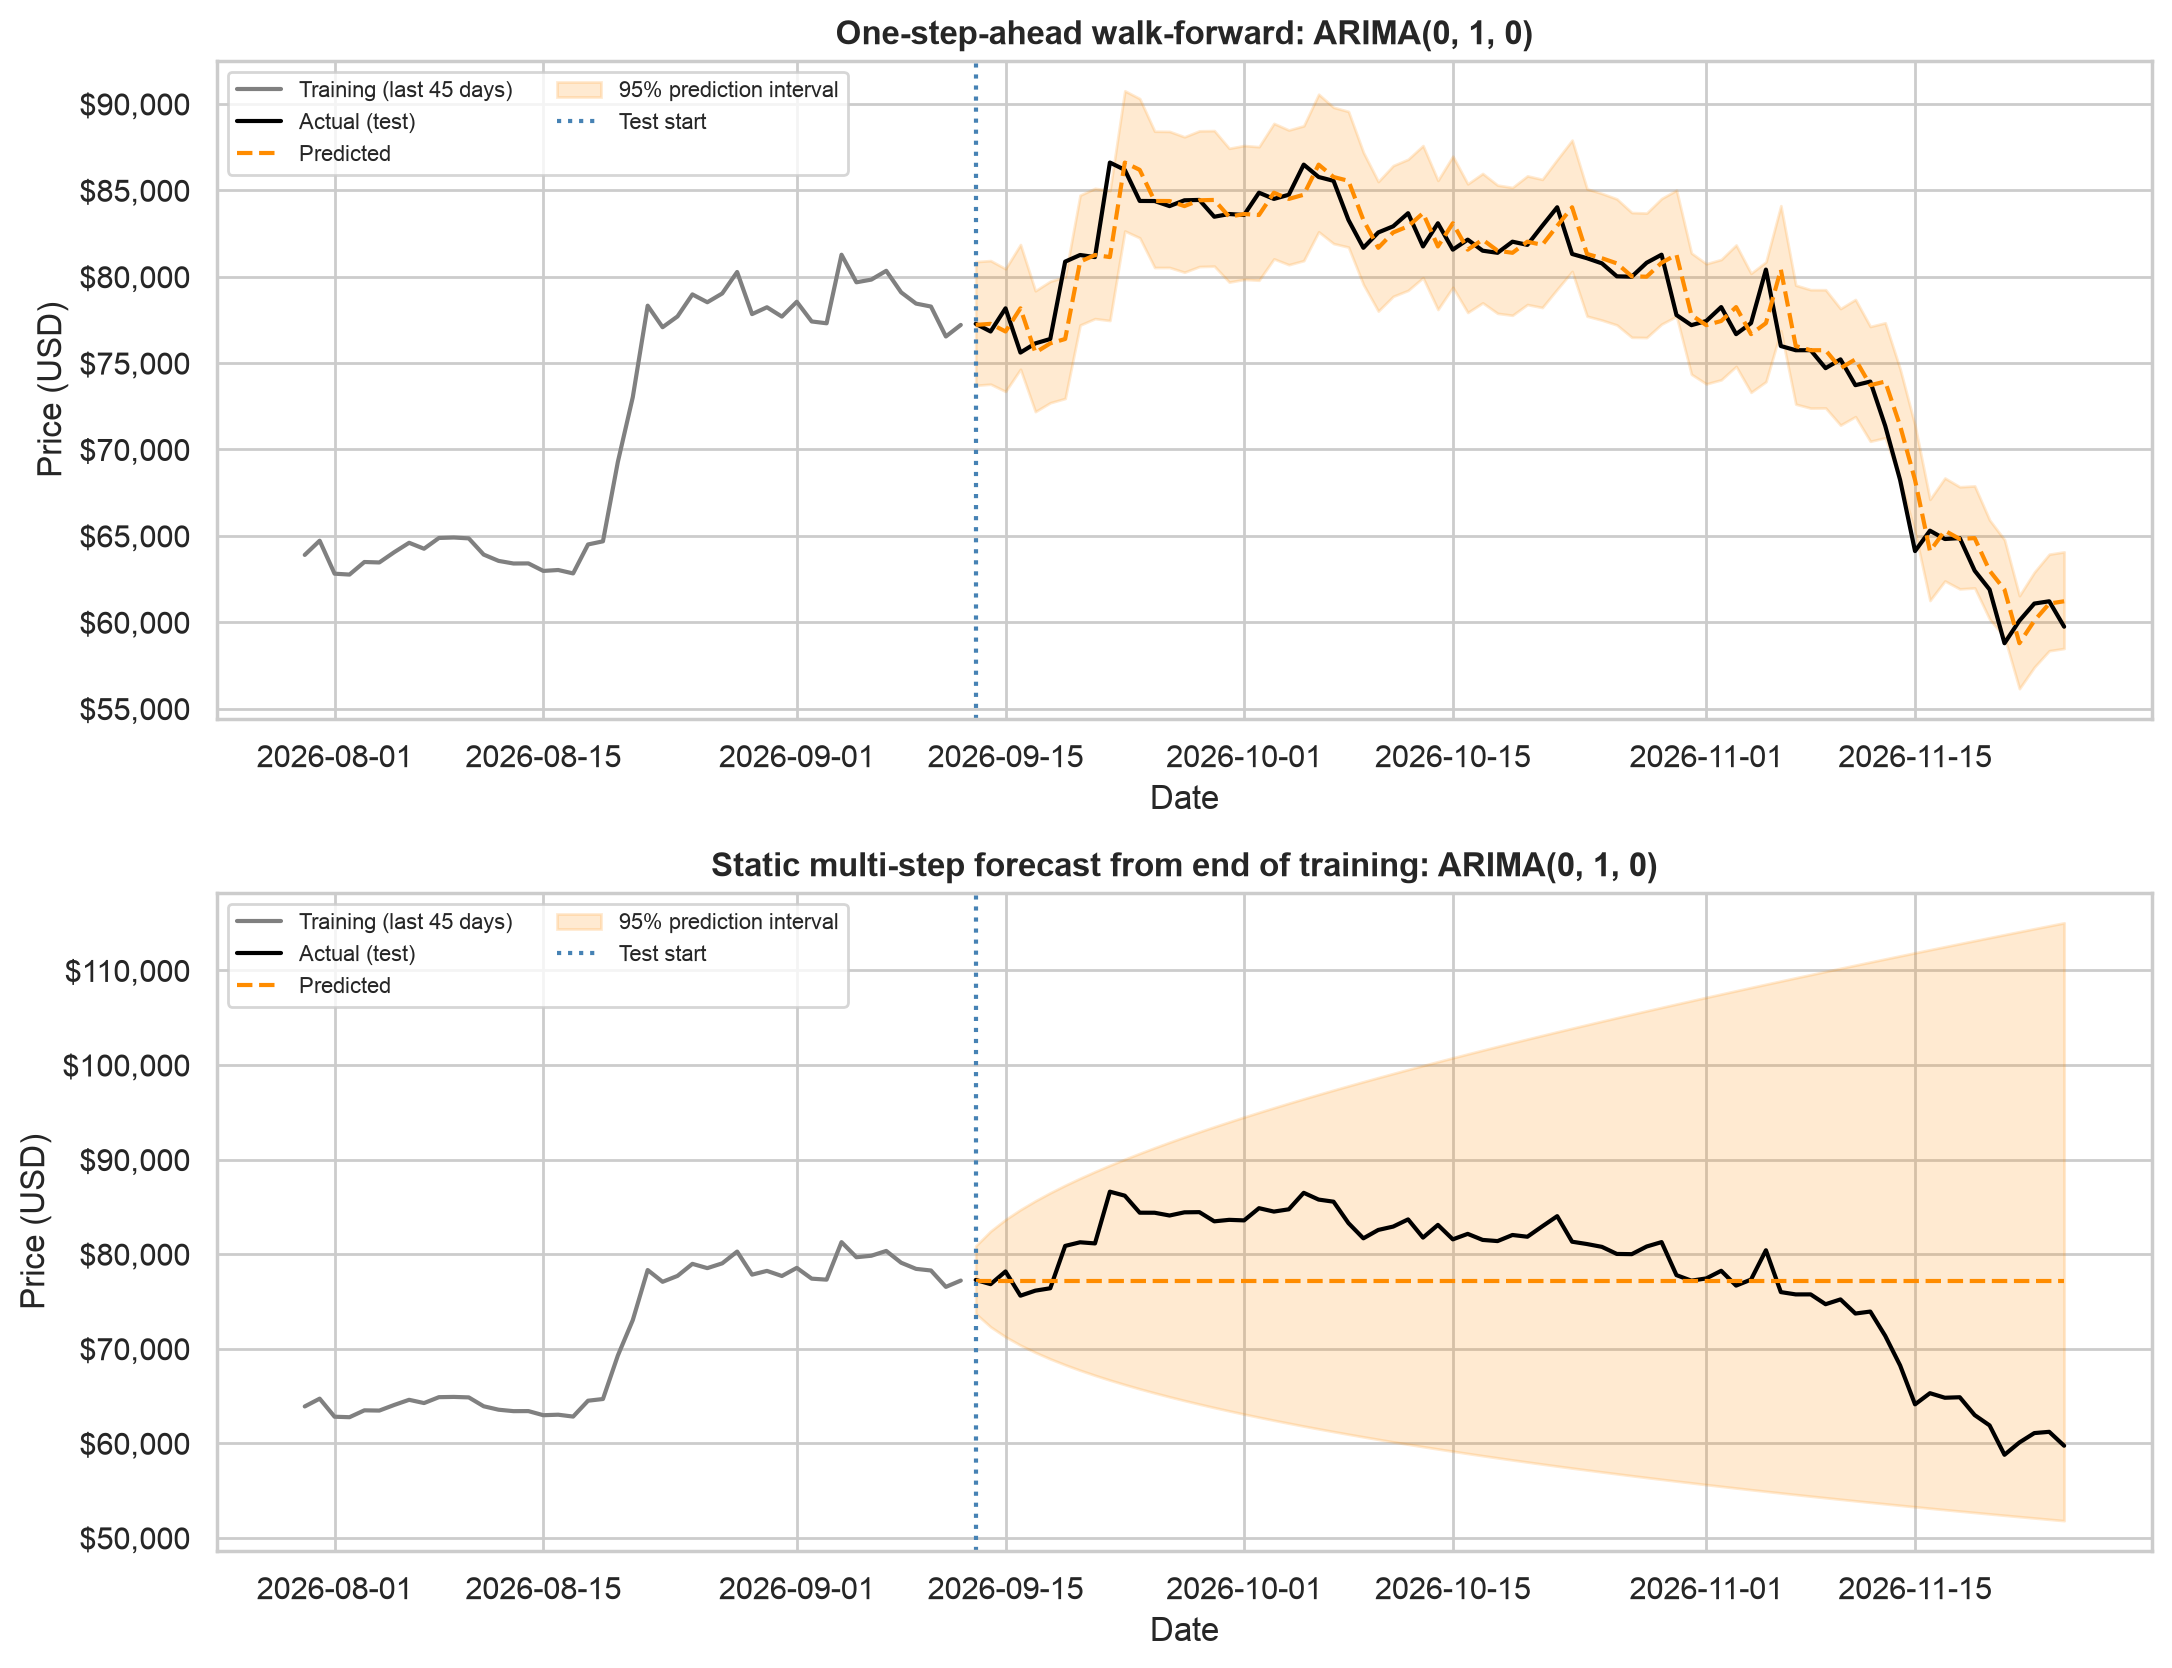

{'one_step': 93.24324324324324, 'weekly': 92.43697478991596, 'static': 100.0, 'weekly_by_horizon': {'1': 94.11764705882352, '2': 97.05882352941177, '3': 95.58823529411765, '4': 91.17647058823529, '5': 91.17647058823529, '6': 89.70588235294117, '7': 88.23529411764706}}


,statistic,p_value
"ARIMA(6, 1, 4)",-0.016574,0.986822
"ARIMA(6, 1, 5)",0.318951,0.750675
"ARIMA(4, 1, 4)",-0.799706,0.426476
"ARIMA(4, 1, 5)",-0.892175,0.375231
"ARIMA(3, 1, 2)",-0.406871,0.685293
"ARIMA(1, 1, 0)",0.088552,0.929680
"ARIMA(0, 1, 1)",0.105032,0.916639
"ARIMA(1, 1, 1)",0.465752,0.642779
"ARIMA(0, 1, 0) + drift",-1.087596,0.280351
"ARIMA(0, 1, 0)",-1.418633,0.160261


In [15]:
src(am.walk_forward)
print(summary['split']); display(table('model_evaluation.csv').round(3))
display(table('test_predictions_one_step.csv').round(2)); show('test_predictions.png')
print(summary['coverage']); pd.DataFrame(summary['diebold_mariano']).T

The selected random walk **is** the naive forecast, so their errors are identical. Drift is marginally better on a mostly falling test period. No alternative differs significantly from naive (Diebold–Mariano). The one-step line is simply yesterday's price: closeness is not skill.

## 9. Residual diagnostics

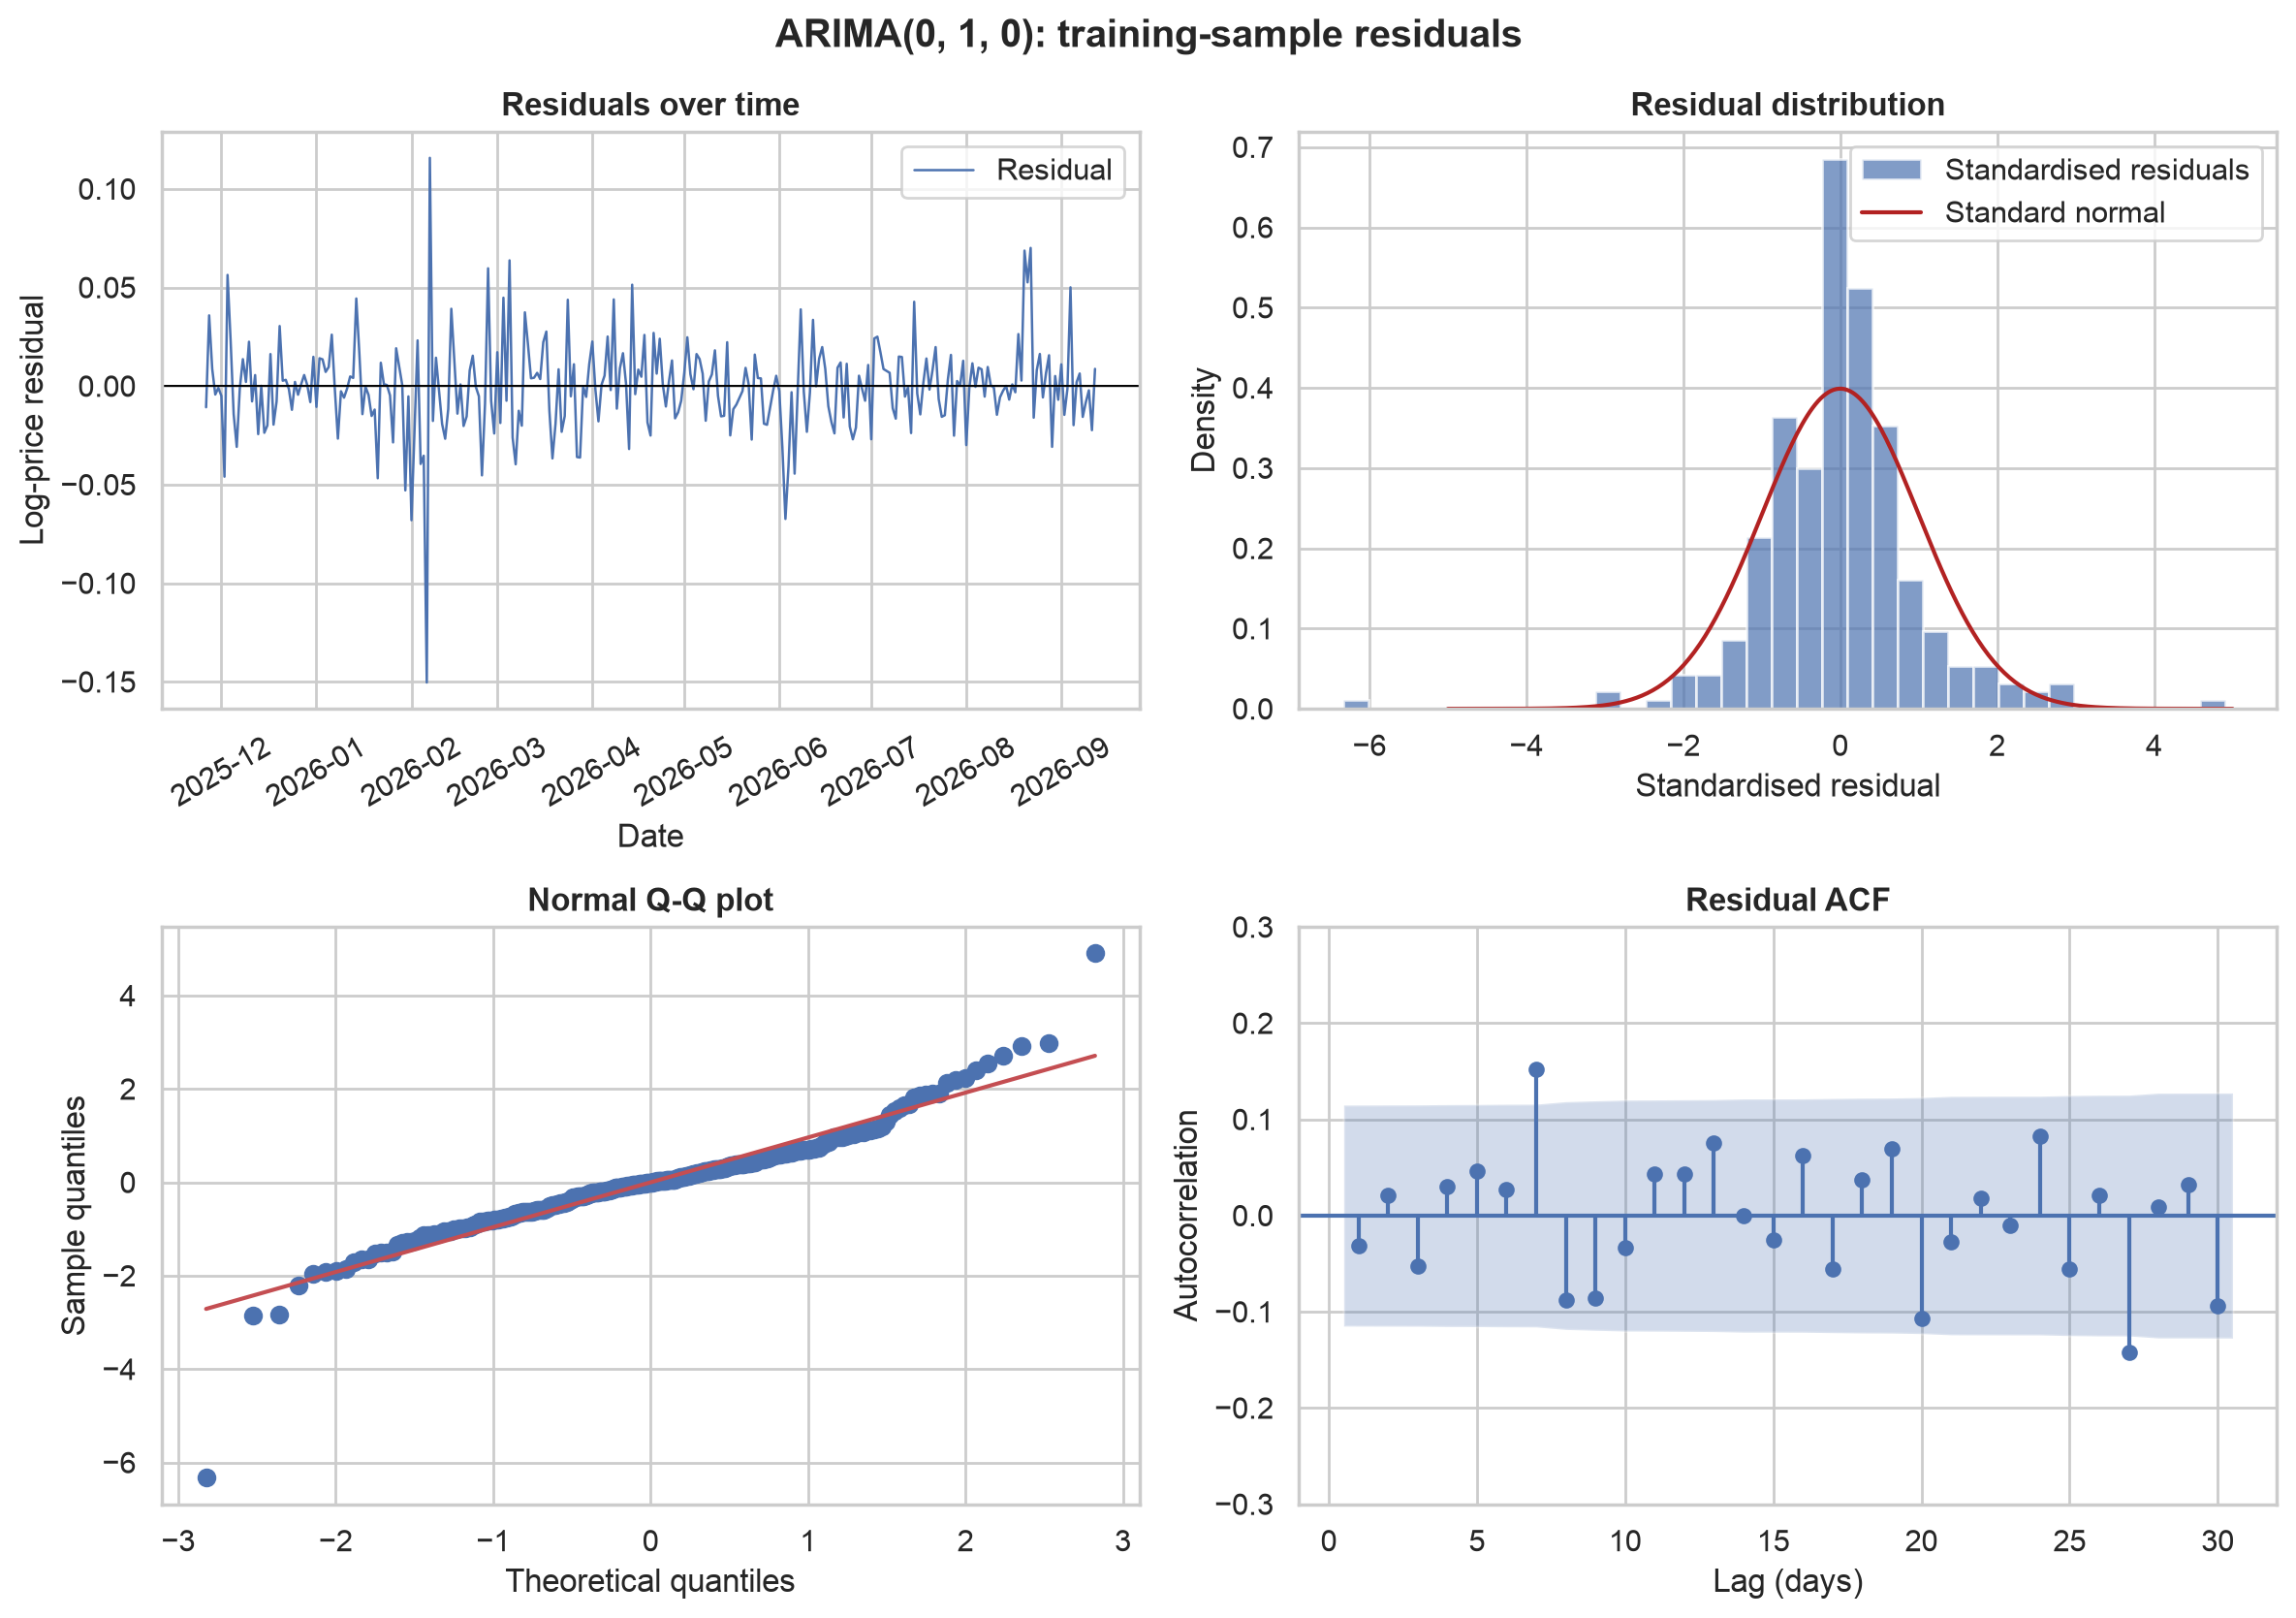

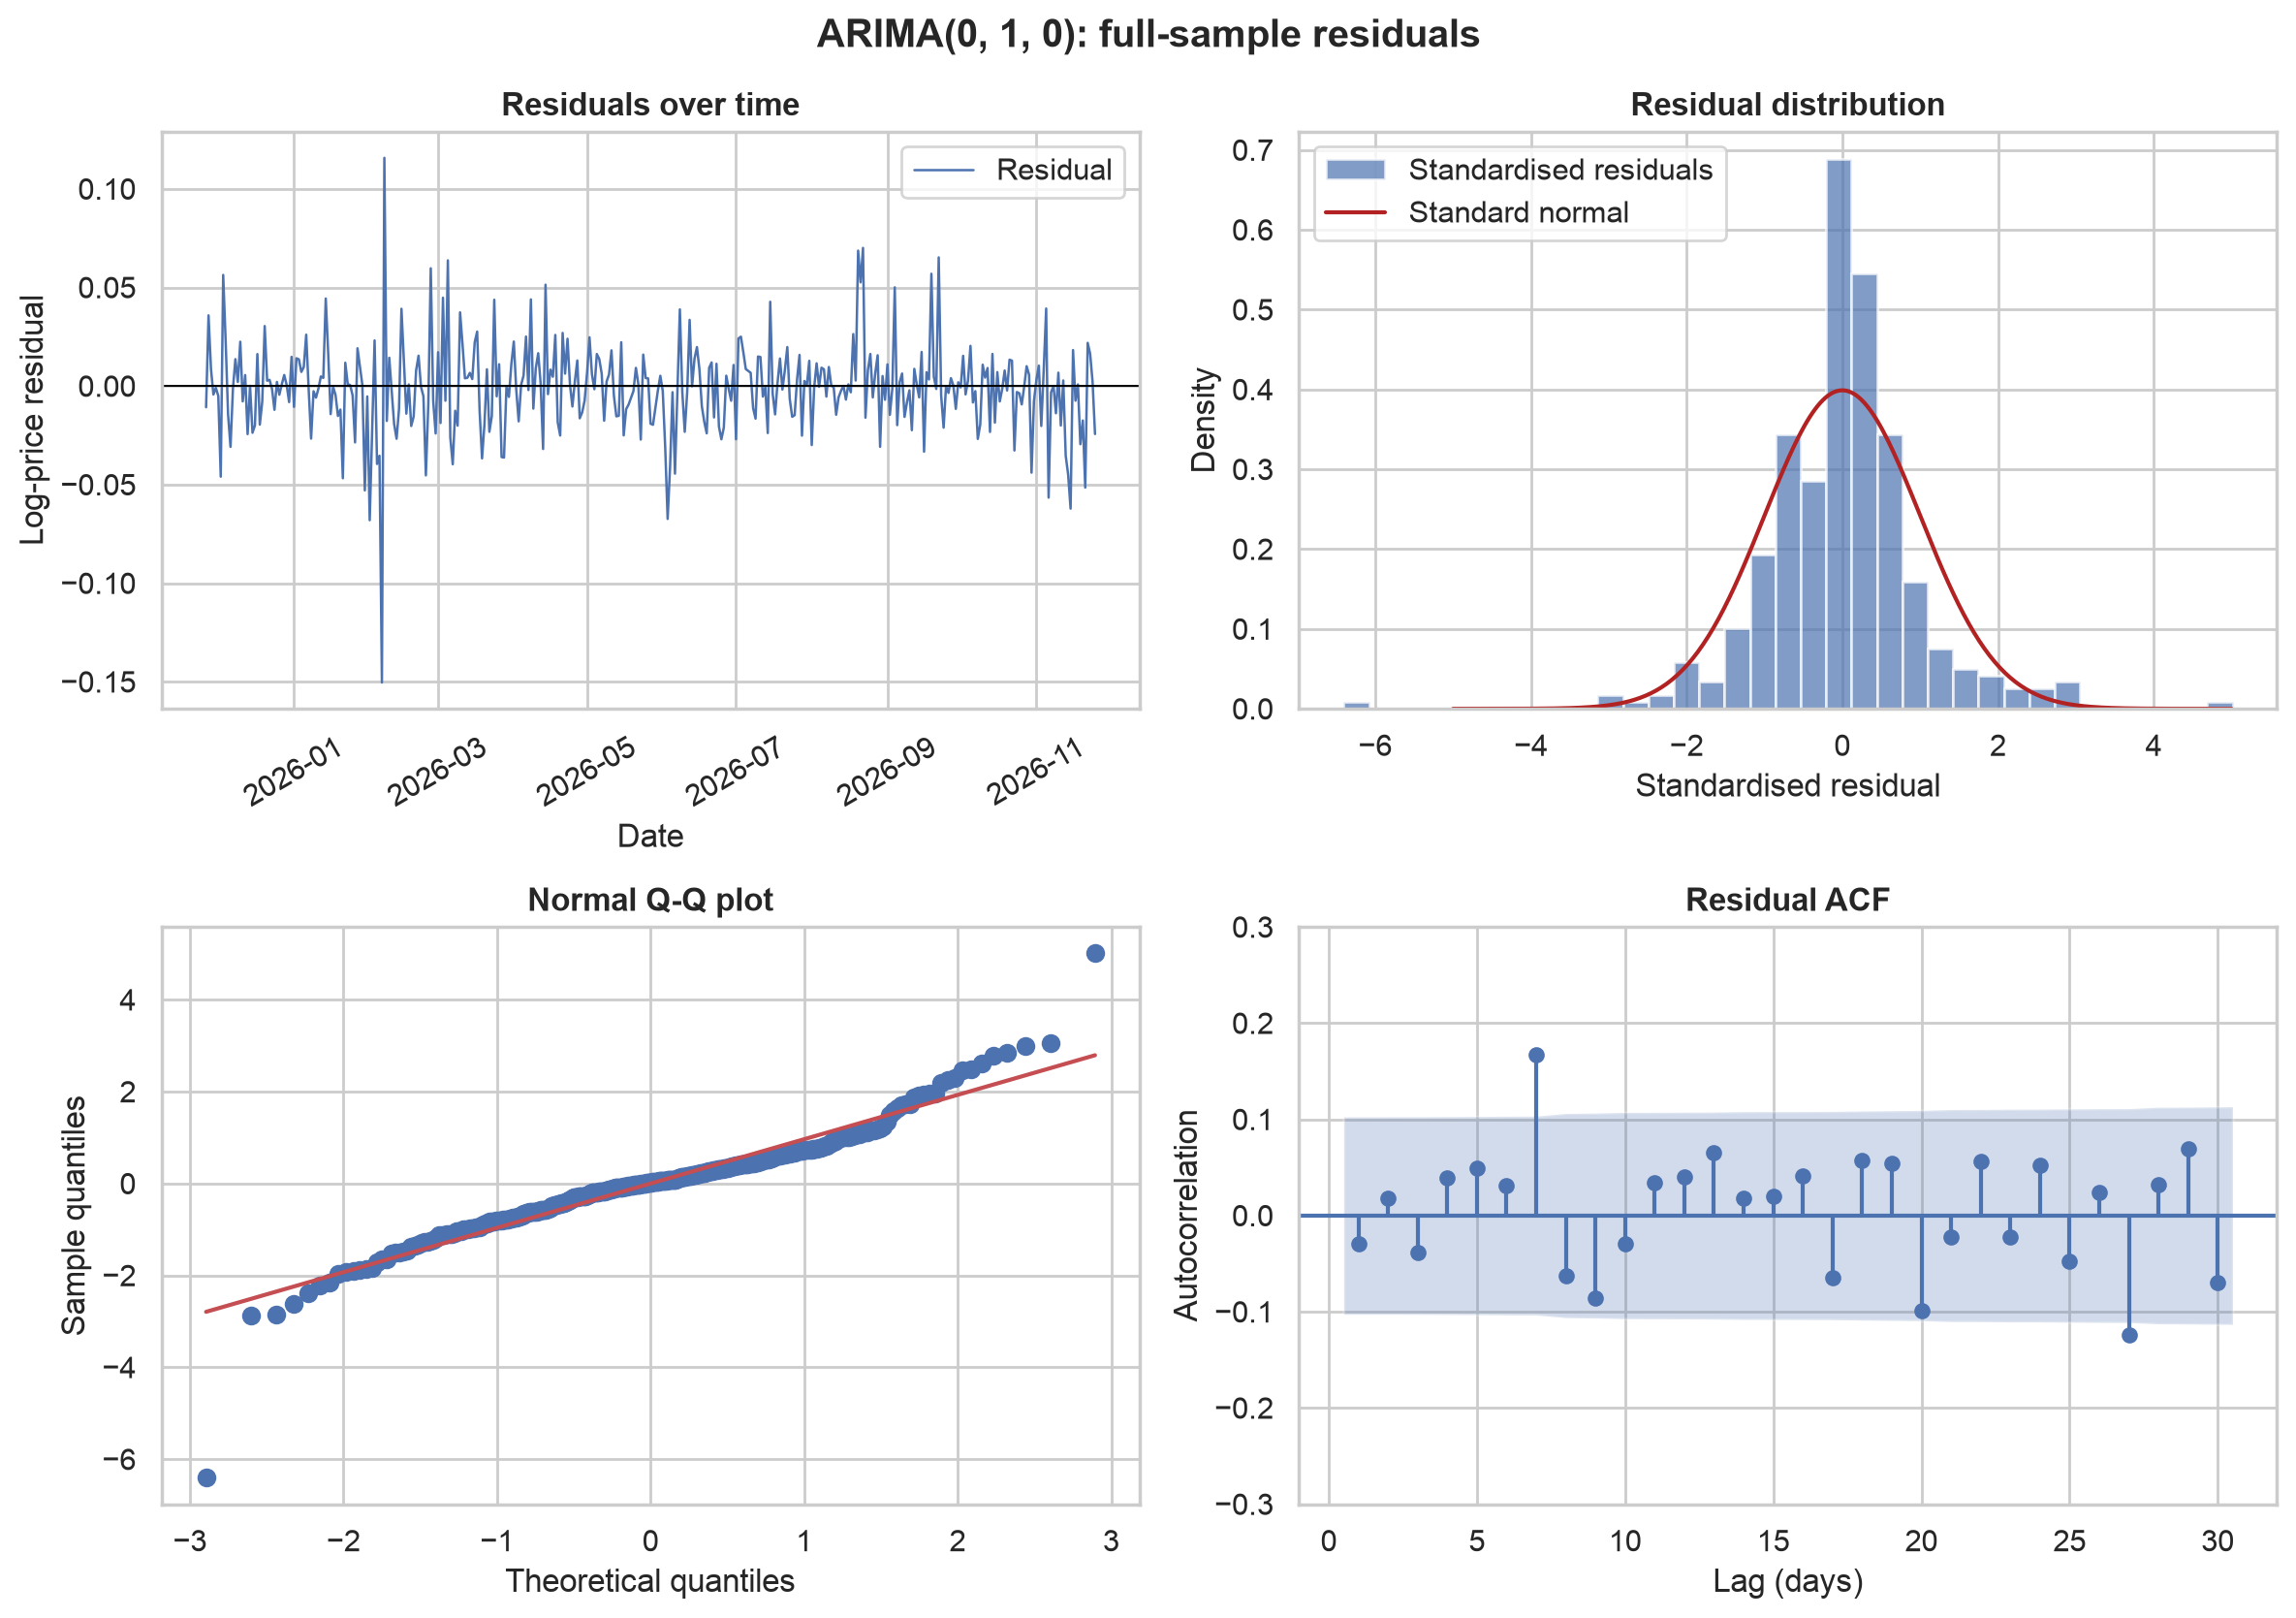

diagnostics_train {'ljung_box': {'10': {'Q': 14.226449312300542, 'p_value': 0.16291087987658334}, '20': {'Q': 25.051872100484673, 'p_value': 0.19945381156120132}}, 'jarque_bera': [636.7332924610153, 5.43403360754935e-139], 'arch_lm': [52.524038847156675, 9.125145548286844e-08], 'ljung_box_squared_10': [52.983056476616376, 7.500091539170481e-08]}
diagnostics_full {'ljung_box': {'10': {'Q': 17.76520797327203, 'p_value': 0.05905578379191137}, '20': {'Q': 29.204825245650255, 'p_value': 0.08380394373976366}}, 'jarque_bera': [623.104478331178, 4.94973223709422e-136], 'arch_lm': [58.129333473893396, 8.173254495918107e-09], 'ljung_box_squared_10': [59.26806617936892, 4.984260678832933e-09]}


In [16]:
show('model_diagnostics.png'); show('model_diagnostics_full_sample.png')
for key in ('diagnostics_train', 'diagnostics_full'):
    x = summary[key]; print(key, {k: x[k] for k in ('ljung_box', 'jarque_bera', 'arch_lm', 'ljung_box_squared_10')})

Ljung–Box does not reject at 5% (full-sample lag 10 is borderline; there is a lag-7 spike). Residuals are **not** Gaussian i.i.d.: heavy tails and ARCH effects are strong. The mean model is acceptable, but the intervals are only approximate.

## 10. Seven-day forecast

,forecast_date,horizon_days,predicted_price_usd,lower_95_usd,upper_95_usd,expected_daily_change_pct,cumulative_change_pct,direction
0,2026-11-26,1,59742.21,57075.6384,62533.3638,0.0,0.0,Neutral
1,2026-11-27,2,59742.21,56006.2780,63727.3495,0.0,0.0,Neutral
2,2026-11-28,3,59742.21,55199.3340,64658.9623,0.0,0.0,Neutral
3,2026-11-29,4,59742.21,54528.0880,65454.9204,0.0,0.0,Neutral
4,2026-11-30,5,59742.21,53943.4752,66164.2885,0.0,0.0,Neutral
5,2026-12-01,6,59742.21,53420.3414,66812.2210,0.0,0.0,Neutral
6,2026-12-02,7,59742.21,52943.7492,67413.6552,0.0,0.0,Neutral


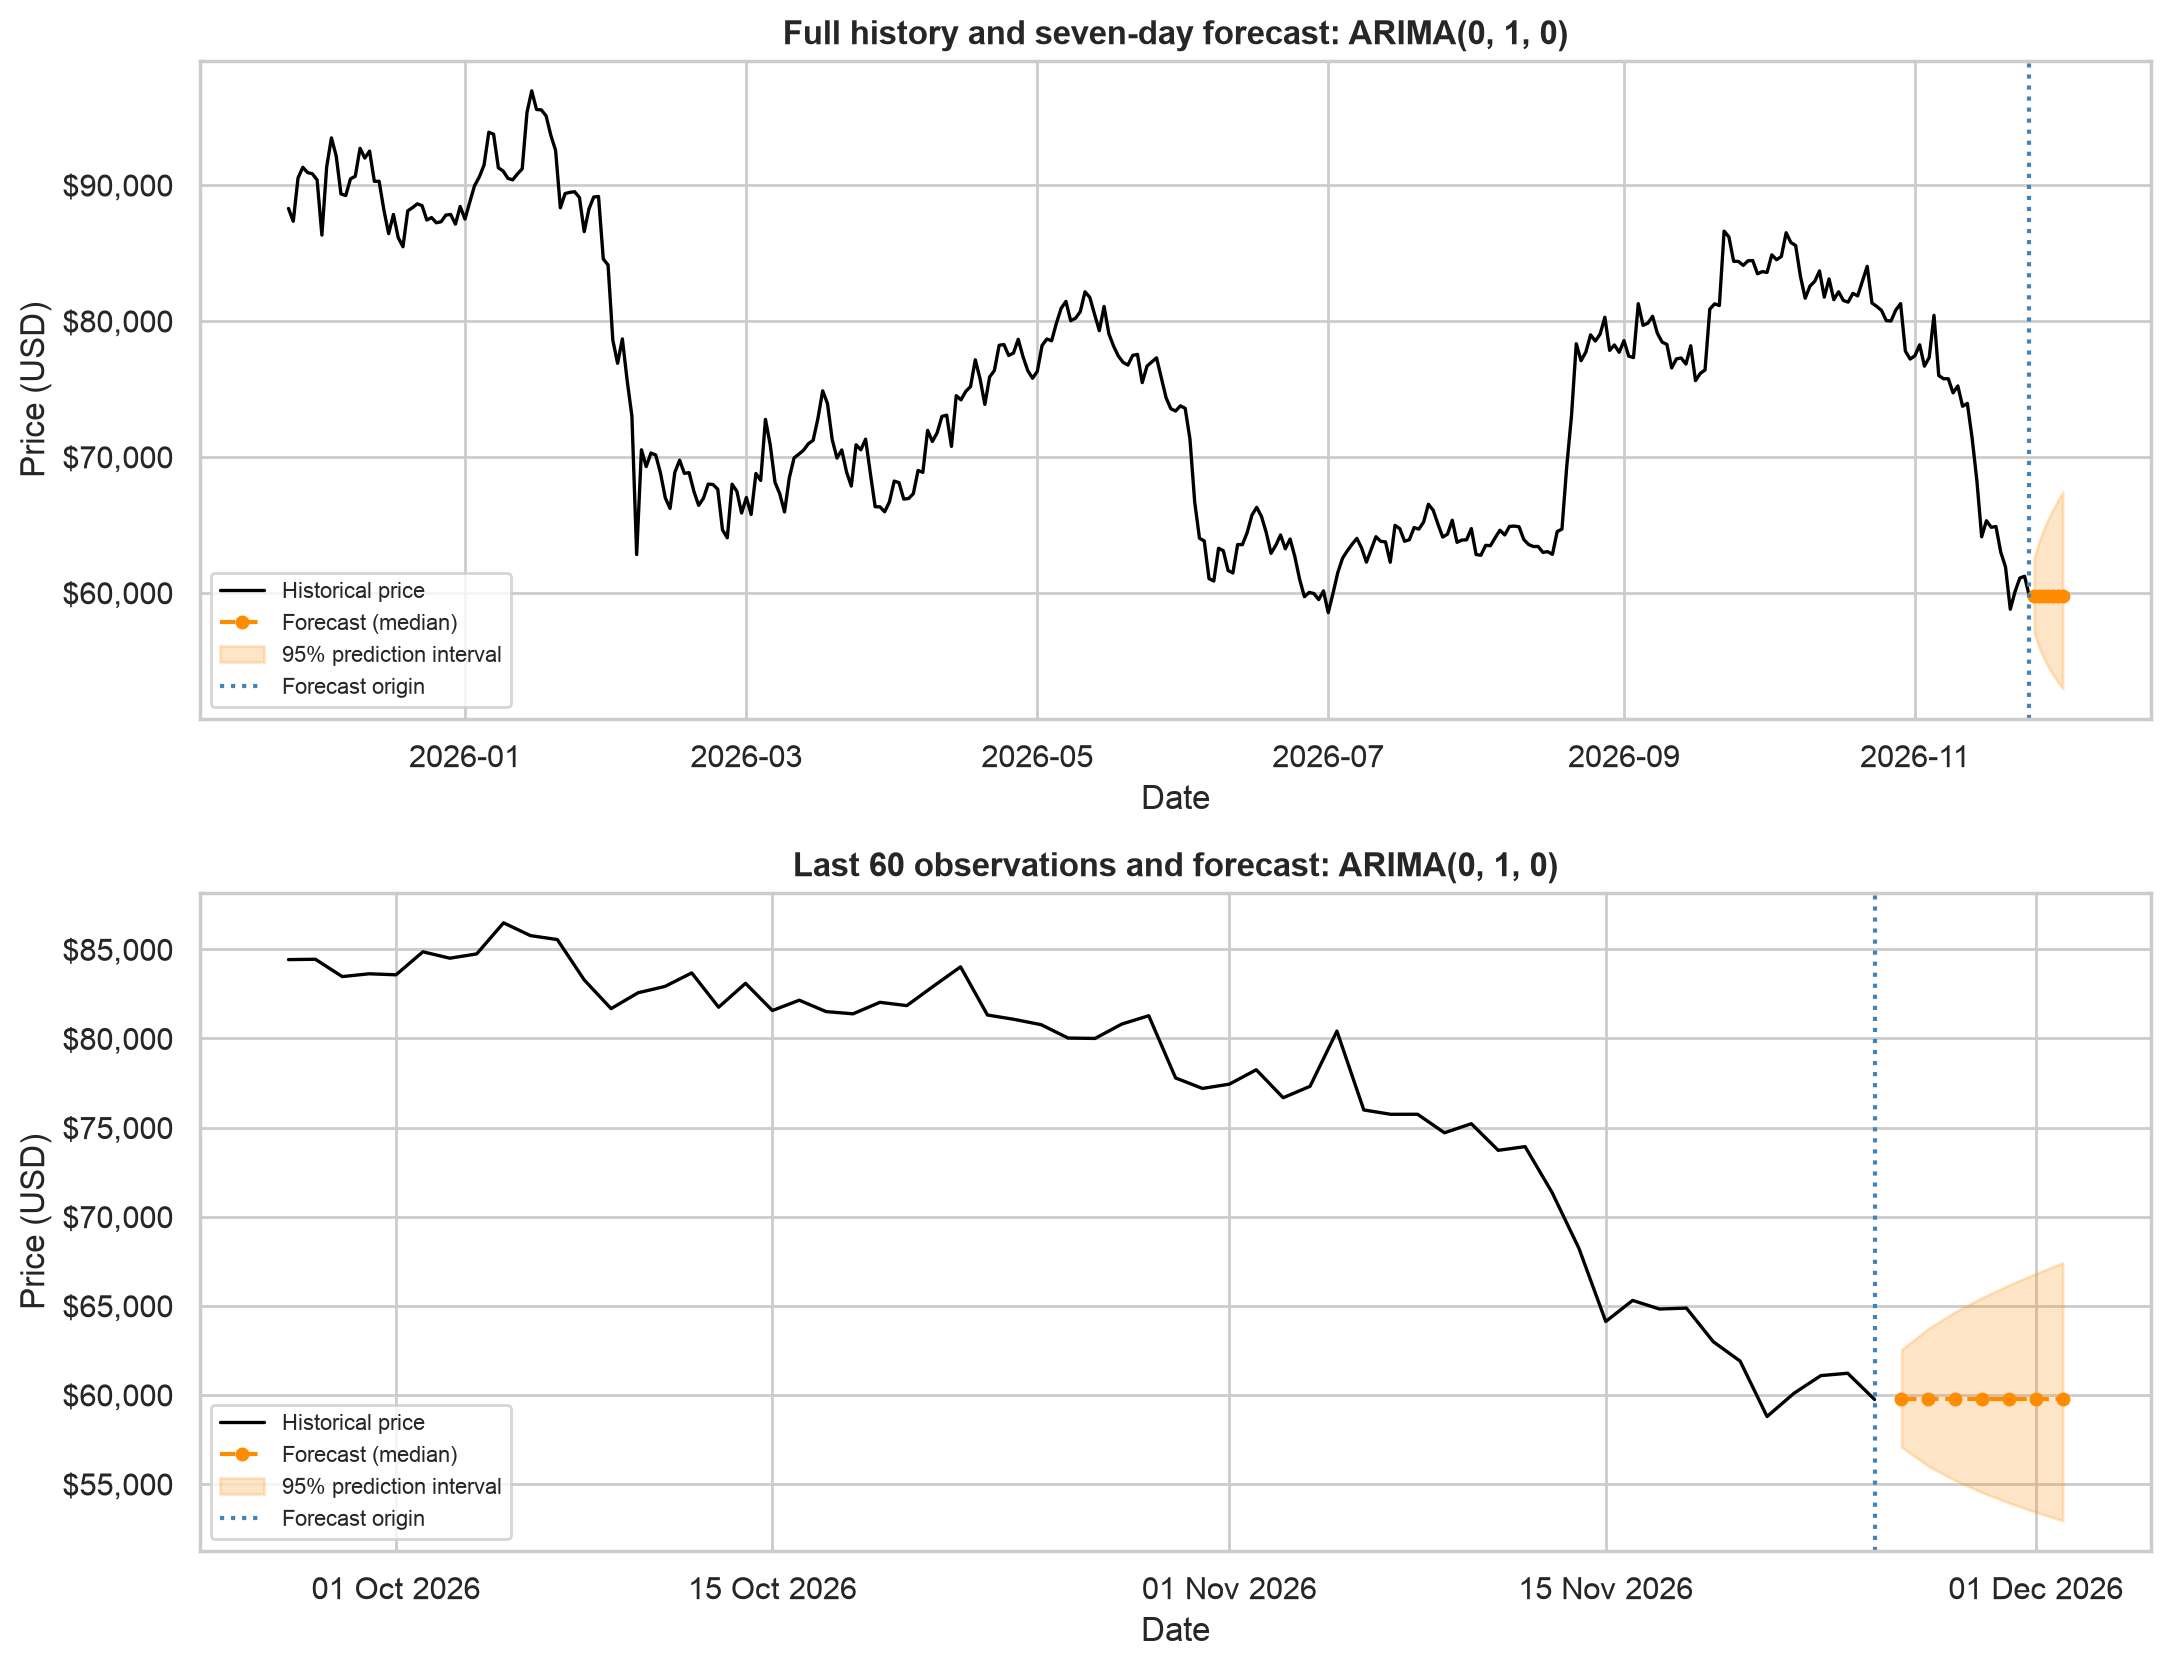

{'origin_date': '2026-11-25',
 'origin_price': 59742.21,
 'end_price': 59742.20999999995,
 'change_pct': 0.0,
 'classification': 'Neutral',
 'width_day1': 5457.725412739106,
 'width_day7': 14469.905965879385,
 'width_day7_pct': 24.220573637766996,
 'lower_day7': 52943.749232623595,
 'upper_day7': 67413.65519850298,
 'mean_adjusted_day7': 59855.8064473767,
 'log_se_day7': 0.06163827090303776}

In [17]:
display(table('seven_day_forecast.csv')); show('seven_day_forecast.png'); summary['forecast']

### Sensitivity: the model chosen without the root screen

In [18]:
display(table('sensitivity_forecast_without_root_screen.csv')); print(summary['sensitivity']['model'])

,forecast_date,horizon_days,predicted_price_usd,lower_95_usd,upper_95_usd,expected_daily_change_pct,cumulative_change_pct,direction
0,2026-11-26,1,59419.1637,56876.4101,62075.5952,-0.5407,-0.5407,Down
1,2026-11-27,2,58839.0469,55379.3190,62514.9153,-0.9763,-1.5118,Down
2,2026-11-28,3,59038.4815,54824.6855,63576.1475,0.3389,-1.1779,Up
3,2026-11-29,4,58815.8611,54042.9902,64010.2539,-0.3771,-1.5506,Down
4,2026-11-30,5,58948.4694,53531.8980,64913.1110,0.2255,-1.3286,Up
5,2026-12-01,6,59425.1595,53308.3056,66243.8909,0.8087,-0.5307,Up
6,2026-12-02,7,59274.2109,52564.0197,66841.0083,-0.2540,-0.7834,Down


ARIMA(6, 1, 4)


## 11. Interpretation
* **Neutral.** The selected model's median forecast is flat at the last observed price (0% expected change).
* The seven-day 95% interval is about 24% of the price wide: large moves in either direction are consistent with the model.
* The sensitivity model is also Neutral over seven days (about −0.8%), with daily directions that are small relative to uncertainty.
* There is **no statistically meaningful directional signal**. ARIMA cannot guarantee market direction.

## 12. Limitations
One year of univariate data; linear model; non-constant variance and heavy tails; short validation and test windows; post-hoc root screen.